Developing Retention Models for Credit Card Customers

In [5]:
# data manipulation
import pandas as pd
import numpy as np

# data viz
import matplotlib.pyplot as plt
from matplotlib import rcParams
import seaborn as sns

# apply some cool styling
plt.style.use("ggplot")
rcParams['figure.figsize'] = (12, 6)

# use sklearn to import a dataset
from sklearn.datasets import load_wine

#import frequently used libraries- hocadan aldıklarım 
import math
from scipy.stats import norm
from scipy.stats import lognorm
from scipy.stats import chi2
from scipy.stats import t
from scipy.stats import f

import scipy.stats as sc 
import statsmodels.graphics.gofplots as sm 
#pip install bbplot 

TRAINING DATA

In [15]:
df=pd.read_excel("training_data_set-final.xlsx")

print(df) #shows the content of the file or, if the file is large, the first and last 5 rows of the file

print(df.columns) #shows the names of the columns, which you will use to refer 

       CAT1  CAT2  CAT3  CAT4  CAT5  CAT6  CAT7  CAT8  CAT9  CAT10  ...  \
0       7.0    12     7   7.0  11.0     3    55    10   7.0      3  ...   
1       2.0     4     3   4.0  33.0     1    49    10   7.0      2  ...   
2       7.0     8     4   1.0  67.0     3    53    10   0.0      4  ...   
3       4.0     8     7   3.0  52.0     1    49    10   0.0      4  ...   
4       2.0     8     4   1.0  40.0     3    54     7   0.0      4  ...   
...     ...   ...   ...   ...   ...   ...   ...   ...   ...    ...  ...   
49995   3.0     3     7   2.0   7.0     1    55    10   0.0      2  ...   
49996   2.0     8     7   3.0  78.0     2    55    10   7.0      4  ...   
49997   4.0     6     9   1.0   7.0     2     1     9   0.0      5  ...   
49998   5.0     1     3   4.0  40.0     1    36    10   1.0      2  ...   
49999   5.0     1     4   6.0  73.0     1    49     2   0.0      2  ...   

       NUM19  NUM20  NUM21  NUM22  NUM23  NUM24  NUM25     NUM26     NUM27  \
0          1      2  

In [16]:
df.head()


,CAT1,CAT2,CAT3,CAT4,CAT5,CAT6,CAT7,CAT8,CAT9,CAT10,...,NUM19,NUM20,NUM21,NUM22,NUM23,NUM24,NUM25,NUM26,NUM27,TARGET
0,7.0,12,7,7.0,11.0,3,55,10,7.0,3,...,1,2,1,1,0.6,0,2,0.039196,NaN,0
1,2.0,4,3,4.0,33.0,1,49,10,7.0,2,...,11,6,8,13,0.6,1,0,NaN,NaN,0
2,7.0,8,4,1.0,67.0,3,53,10,0.0,4,...,4,6,6,4,0.6,7,6,0.026348,0.089032,0
3,4.0,8,7,3.0,52.0,1,49,10,0.0,4,...,7,7,5,10,0.6,5,5,0.031773,0.087314,0
4,2.0,8,4,1.0,40.0,3,54,7,0.0,4,...,5,6,4,8,0.6,0,0,0.023150,NaN,0


In [17]:
df.tail()

,CAT1,CAT2,CAT3,CAT4,CAT5,CAT6,CAT7,CAT8,CAT9,CAT10,...,NUM19,NUM20,NUM21,NUM22,NUM23,NUM24,NUM25,NUM26,NUM27,TARGET
49995,3.0,3,7,2.0,7.0,1,55,10,0.0,2,...,7,9,7,8,0.2,0,11,0.038615,0.096702,0
49996,2.0,8,7,3.0,78.0,2,55,10,7.0,4,...,3,8,5,8,0.2,0,6,NaN,NaN,0
49997,4.0,6,9,1.0,7.0,2,1,9,0.0,5,...,3,7,4,5,0.2,8,5,0.046931,NaN,0
49998,5.0,1,3,4.0,40.0,1,36,10,1.0,2,...,11,11,12,12,0.2,5,12,0.022959,0.089737,0
49999,5.0,1,4,6.0,73.0,1,49,2,0.0,2,...,9,9,9,10,0.2,10,7,NaN,NaN,0


In [18]:
df.shape


(50000, 48)

In [19]:
df.describe()

,CAT1,CAT2,CAT3,CAT4,CAT5,CAT6,CAT7,CAT8,CAT9,CAT10,...,NUM19,NUM20,NUM21,NUM22,NUM23,NUM24,NUM25,NUM26,NUM27,TARGET
count,49973.000000,50000.000000,50000.000000,49966.000000,49899.000000,50000.000000,50000.000000,50000.000000,49966.000000,50000.000000,...,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,37736.000000,27064.000000,50000.000000
mean,4.331739,6.377440,4.120960,3.588060,36.977655,1.710360,39.894740,7.721560,1.634892,2.975540,...,6.162120,5.661840,5.641640,7.670020,0.332555,3.17898,4.727060,0.033617,0.095512,0.092480
std,1.886627,4.810281,1.742914,2.079256,20.167799,0.790975,17.184244,3.284224,2.688998,1.140249,...,3.929487,3.374954,4.137473,4.014371,0.333326,3.44985,4.180731,0.009783,0.006315,0.289705
min,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.018290,0.081922,0.000000
25%,3.000000,3.000000,4.000000,2.000000,21.000000,1.000000,29.000000,4.000000,0.000000,2.000000,...,3.000000,2.000000,2.000000,4.000000,0.060000,0.00000,0.000000,0.025810,0.089830,0.000000
50%,5.000000,4.000000,4.000000,3.000000,40.000000,2.000000,49.000000,10.000000,0.000000,2.000000,...,7.000000,7.000000,6.000000,8.000000,0.200000,2.00000,4.000000,0.032236,0.097451,0.000000
75%,6.000000,10.000000,4.000000,6.000000,52.000000,2.000000,55.000000,10.000000,2.000000,4.000000,...,9.000000,8.000000,9.000000,11.000000,0.550000,6.00000,8.000000,0.038840,0.099237,0.000000
max,7.000000,16.000000,9.000000,7.000000,81.000000,3.000000,56.000000,10.000000,7.000000,5.000000,...,13.000000,11.000000,13.000000,13.000000,1.000000,12.00000,14.000000,0.120198,0.146049,1.000000


In [11]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 50 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ID           50000 non-null  int64  
 1   CAT1         50000 non-null  int64  
 2   CAT2         49973 non-null  float64
 3   CAT3         50000 non-null  int64  
 4   CAT4         50000 non-null  int64  
 5   CAT5         49966 non-null  float64
 6   CAT6         49899 non-null  float64
 7   CAT7         50000 non-null  int64  
 8   CAT8         50000 non-null  int64  
 9   CAT9         50000 non-null  int64  
 10  CAT10        49966 non-null  float64
 11  CAT11        50000 non-null  int64  
 12  CAT12        49973 non-null  float64
 13  CAT13        50000 non-null  int64  
 14  CAT14        49973 non-null  float64
 15  CAT15        49973 non-null  float64
 16  CAT16        49973 non-null  float64
 17  CAT17        49973 non-null  float64
 18  CAT18        49973 non-null  float64
 19  CAT1

In [20]:
df.columns = ['cat1', 'cat2', 'cat3', 'cat4', 'cat5', 'cat6', 'cat7','cat8', 'cat9', 'cat10','cat11', 'cat12', 'cat13', 'cat14', 'cat15', 'cat16','cat17', 'cat18', 'cat19','cat20', 'num1', 'num2', 'num3', 'num4', 'num5', 'num6','num7', 'num8', 'num9', 'num10',  'num11', 'num12', 'num13', 'num14', 'num15', 'num16', 'num17', 'num18', 'num19', 'num20','num21', 'num22','num23', 'num24', 'num25', 'num26','num27', 'target']
df.head()
df.tail()


,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9,cat10,...,num19,num20,num21,num22,num23,num24,num25,num26,num27,target
49995,3.0,3,7,2.0,7.0,1,55,10,0.0,2,...,7,9,7,8,0.2,0,11,0.038615,0.096702,0
49996,2.0,8,7,3.0,78.0,2,55,10,7.0,4,...,3,8,5,8,0.2,0,6,NaN,NaN,0
49997,4.0,6,9,1.0,7.0,2,1,9,0.0,5,...,3,7,4,5,0.2,8,5,0.046931,NaN,0
49998,5.0,1,3,4.0,40.0,1,36,10,1.0,2,...,11,11,12,12,0.2,5,12,0.022959,0.089737,0
49999,5.0,1,4,6.0,73.0,1,49,2,0.0,2,...,9,9,9,10,0.2,10,7,NaN,NaN,0


In [21]:
df['num1']= df['num1'].astype(float)
df['num2']= df['num2'].astype(float)
df['num3']= df['num3'].astype(float)
df['num4']= df['num4'].astype(float)
df['num5']= df['num5'].astype(float)
df['num6']= df['num6'].astype(float)
df['num7']= df['num7'].astype(float)
df['num8']= df['num8'].astype(float)
df['num9']= df['num9'].astype(float)
df['num10']= df['num10'].astype(float)
df['num11']= df['num11'].astype(float)
df['num12']= df['num12'].astype(float)
df['num13']= df['num13'].astype(float)
df['num14']= df['num14'].astype(float)
df['num15']= df['num15'].astype(float)
df['num16']= df['num16'].astype(float)
df['num17']= df['num17'].astype(float)
df['num18']= df['num6'].astype(float)
df['num19']= df['num19'].astype(float)
df['num20']= df['num20'].astype(float)
df['num21']= df['num21'].astype(float)
df['num22']= df['num22'].astype(float)
df['num23']= df['num23'].astype(float)
df['num24']= df['num24'].astype(float)
df['num25']= df['num25'].astype(float)
df['num26']= df['num26'].astype(float)
df['num27']= df['num27'].astype(float)

UNDERSTANDING VARIABLES

CATEGORICAL VARIABLES

In [22]:
#understanding of the variables
#categorical variables
#for the target variable
df.target.value_counts()

0    45376
1     4624
Name: target, dtype: int64

In [23]:
#to express as percentage by normalizing 
df.target.value_counts(normalize = True)

0    0.90752
1    0.09248
Name: target, dtype: float64

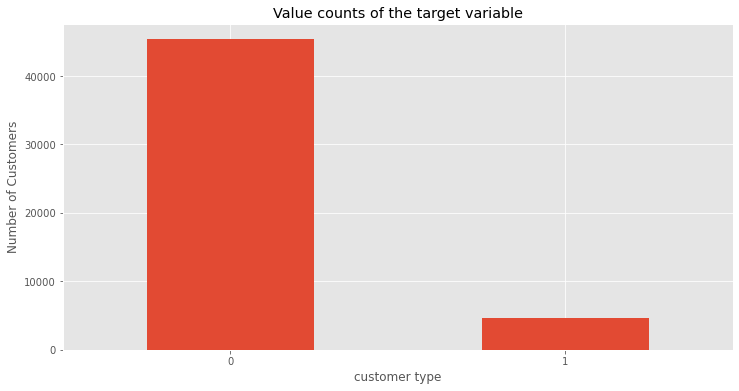

In [24]:
df.target.value_counts().plot(kind="bar")
plt.title("Value counts of the target variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

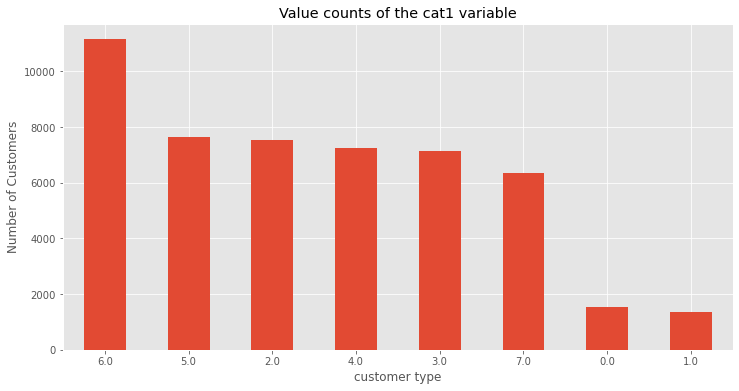

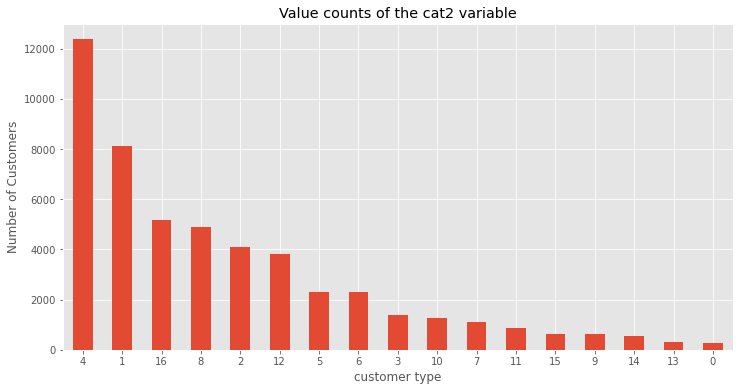

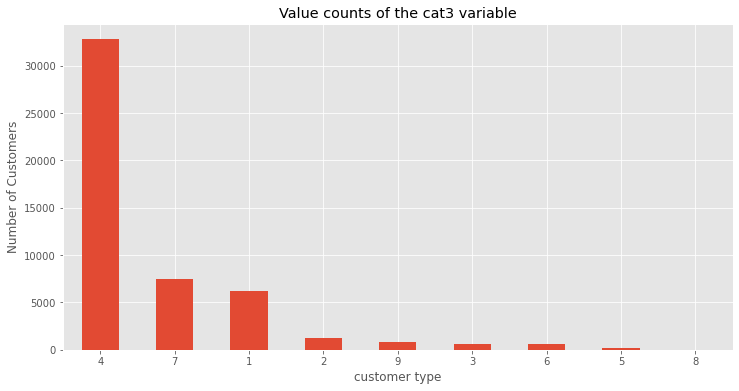

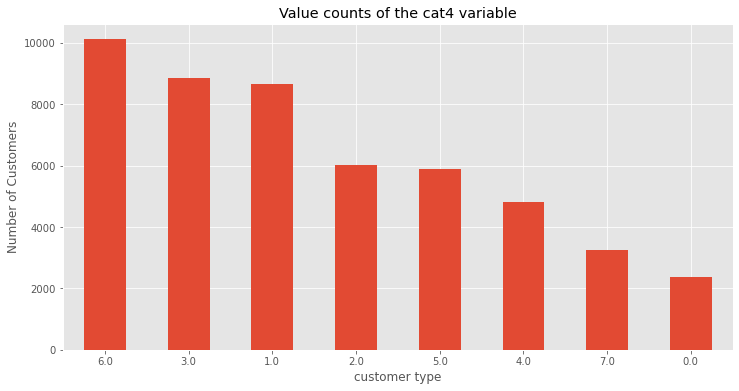

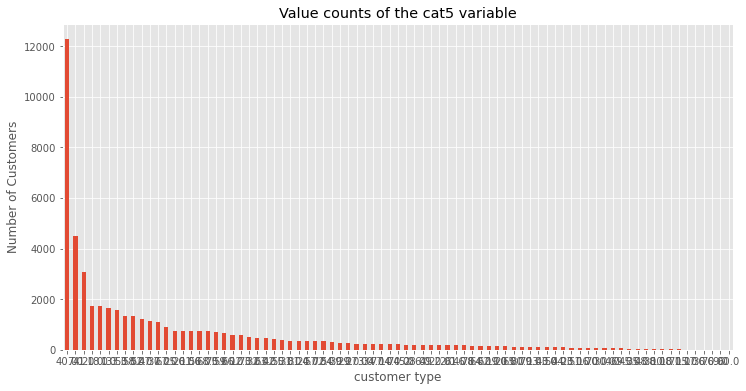

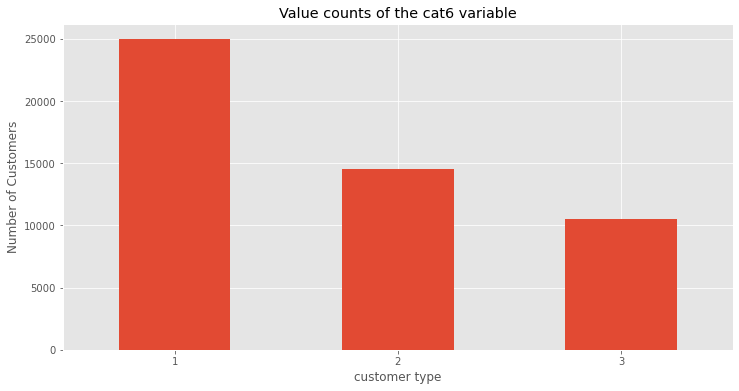

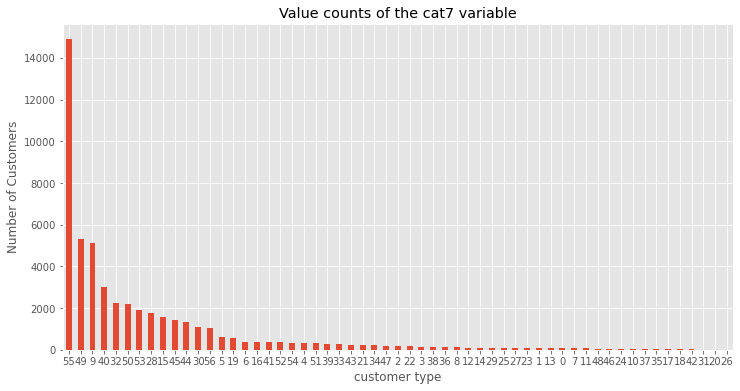

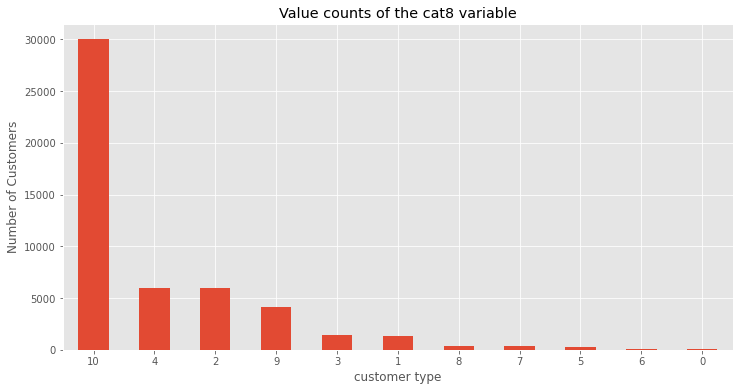

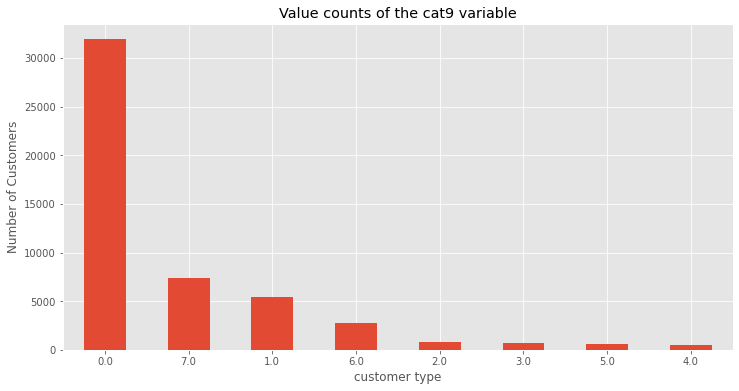

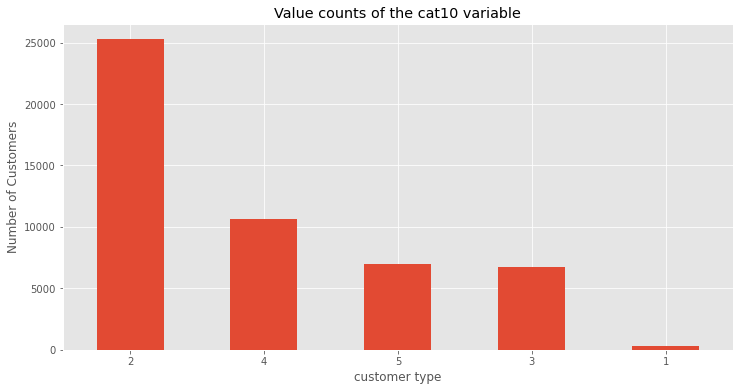

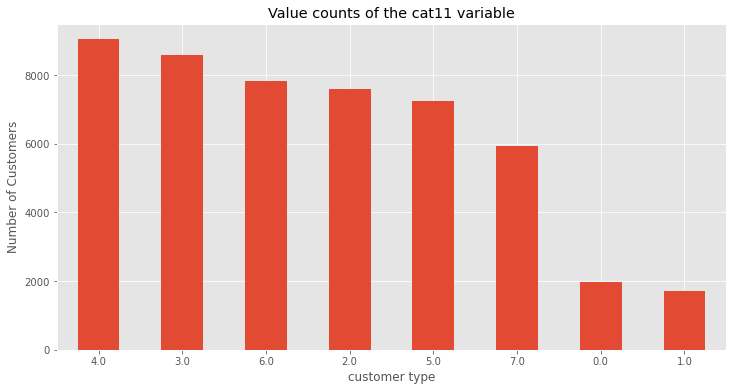

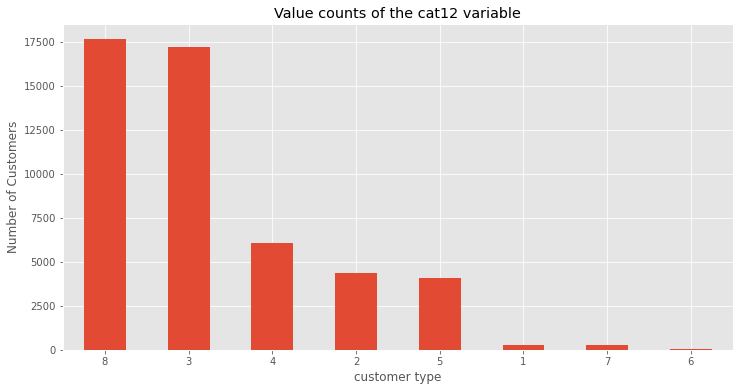

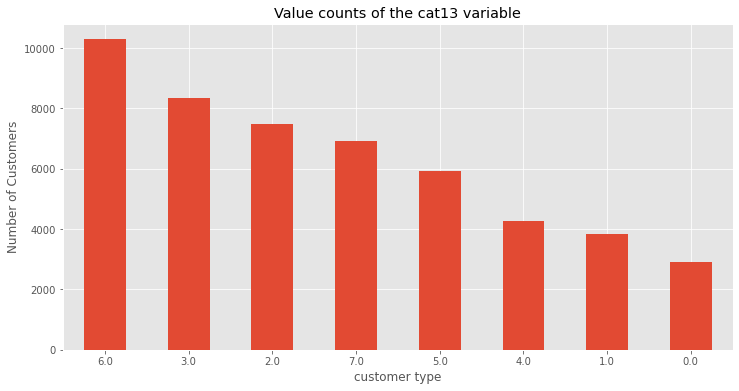

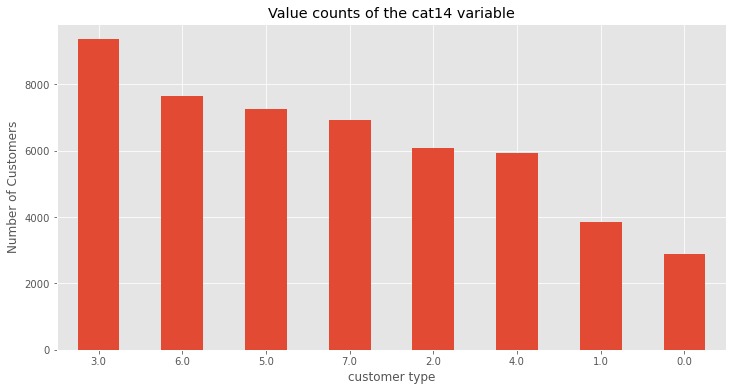

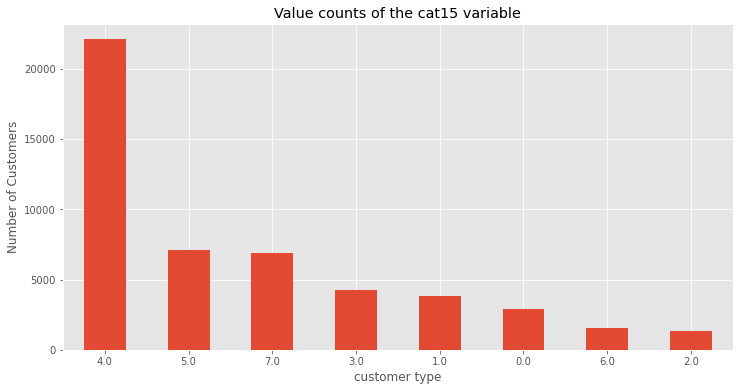

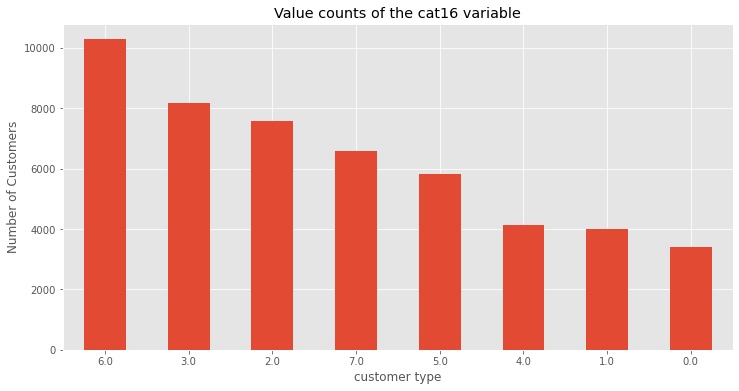

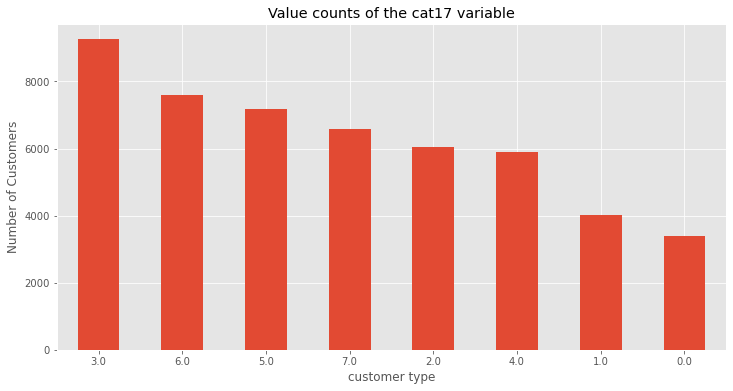

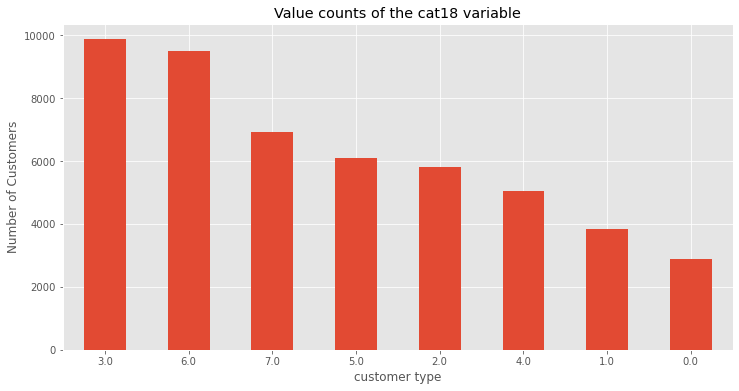

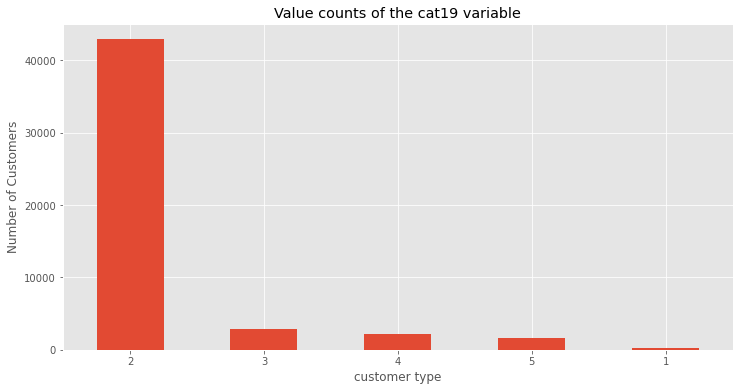

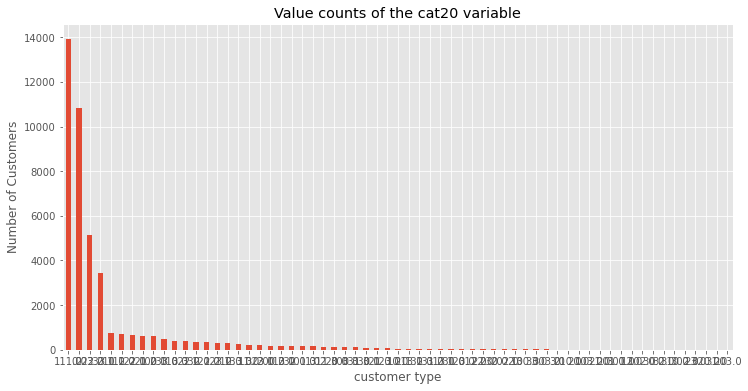

In [25]:
#for the remaining categorical variables starting with cat1 and ending with cat20
df.cat1.value_counts().plot(kind="bar")
plt.title("Value counts of the cat1 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat2.value_counts().plot(kind="bar")
plt.title("Value counts of the cat2 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat3.value_counts().plot(kind="bar")
plt.title("Value counts of the cat3 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat4.value_counts().plot(kind="bar")
plt.title("Value counts of the cat4 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat5.value_counts().plot(kind="bar")
plt.title("Value counts of the cat5 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat6.value_counts().plot(kind="bar")
plt.title("Value counts of the cat6 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat7.value_counts().plot(kind="bar")
plt.title("Value counts of the cat7 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat8.value_counts().plot(kind="bar")
plt.title("Value counts of the cat8 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat9.value_counts().plot(kind="bar")
plt.title("Value counts of the cat9 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat10.value_counts().plot(kind="bar")
plt.title("Value counts of the cat10 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat11.value_counts().plot(kind="bar")
plt.title("Value counts of the cat11 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat12.value_counts().plot(kind="bar")
plt.title("Value counts of the cat12 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()


df.cat13.value_counts().plot(kind="bar")
plt.title("Value counts of the cat13 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat14.value_counts().plot(kind="bar")
plt.title("Value counts of the cat14 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat15.value_counts().plot(kind="bar")
plt.title("Value counts of the cat15 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat16.value_counts().plot(kind="bar")
plt.title("Value counts of the cat16 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat17.value_counts().plot(kind="bar")
plt.title("Value counts of the cat17 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat18.value_counts().plot(kind="bar")
plt.title("Value counts of the cat18 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat19.value_counts().plot(kind="bar")
plt.title("Value counts of the cat19 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat20.value_counts().plot(kind="bar")
plt.title("Value counts of the cat20 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

HEAT MAP FOR CATEGORIC VARIABLES

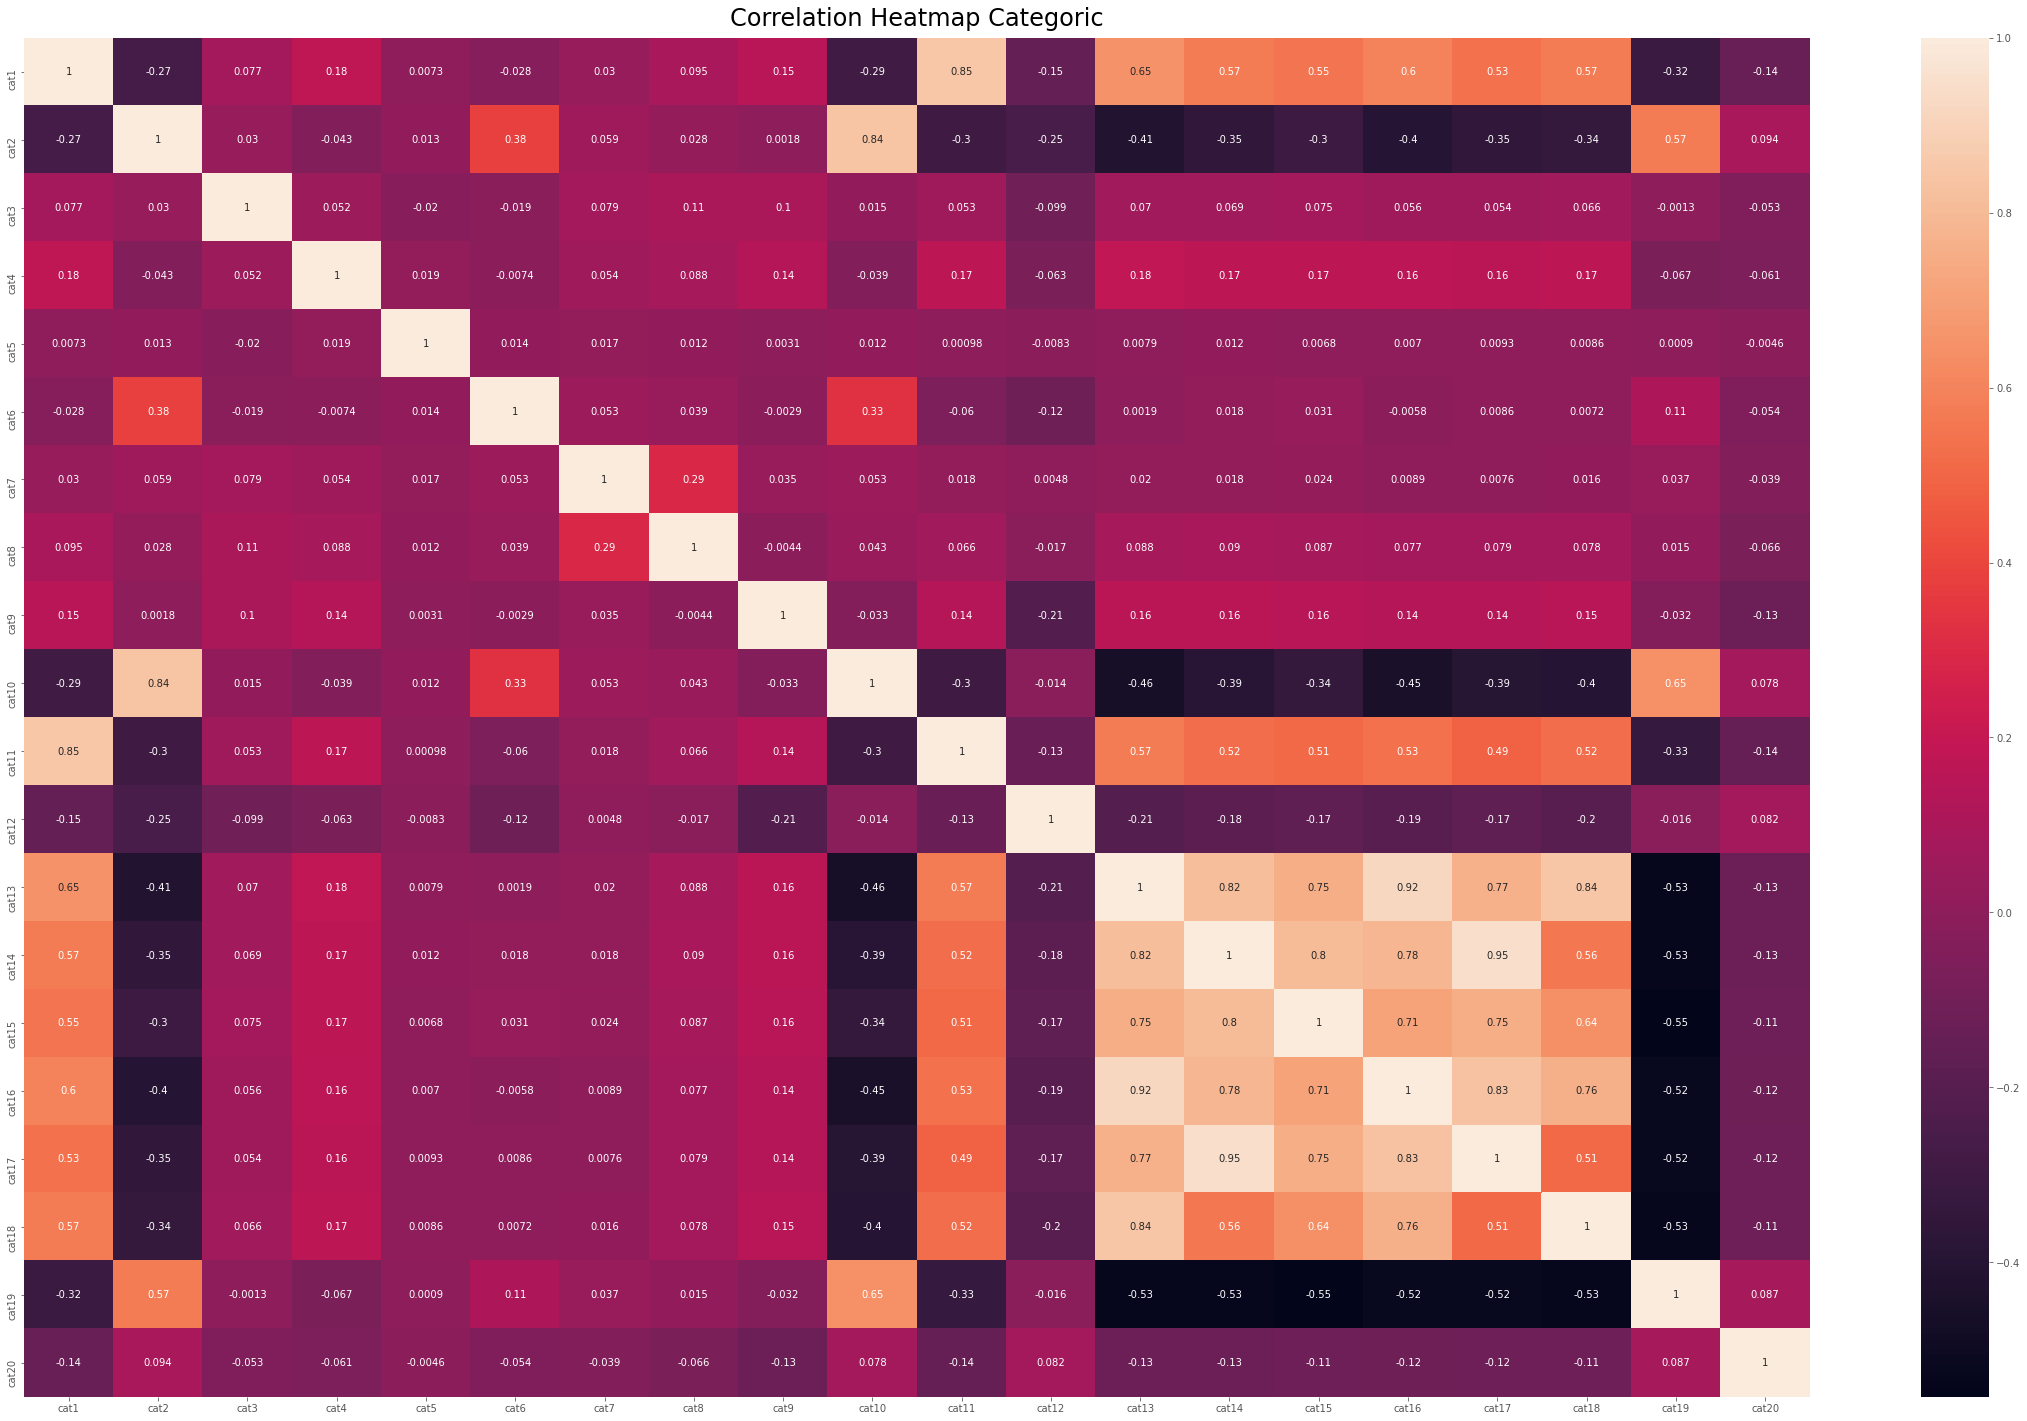

In [26]:
#heatmap for only categoric variables
data_cat = df.iloc[:,0:20]
plt.figure(figsize=(40, 25))
heatmap=sns.heatmap(data_cat.corr(method='spearman'), annot=True,yticklabels=data_cat.columns,xticklabels=data_cat.columns)
heatmap.set_title('Correlation Heatmap Categoric', fontdict={'fontsize':24}, pad=12);

BOX PLOT FOR CATEGORIC VARIABLES

Text(0.5, 1.0, 'CAT20')

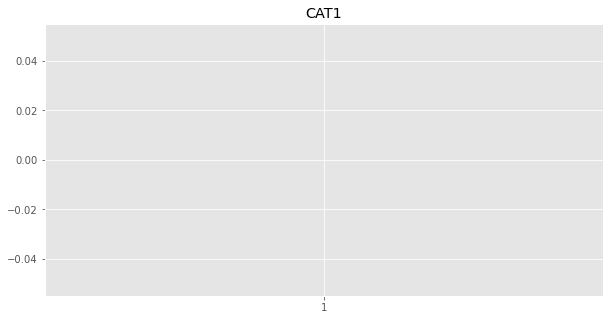

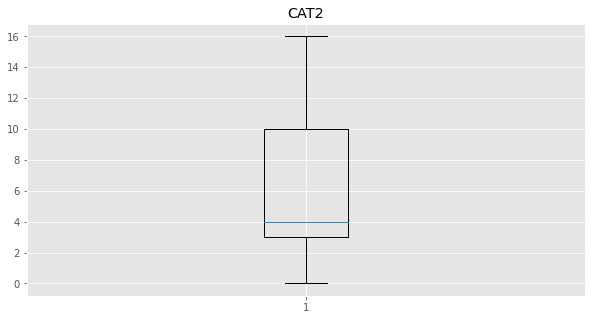

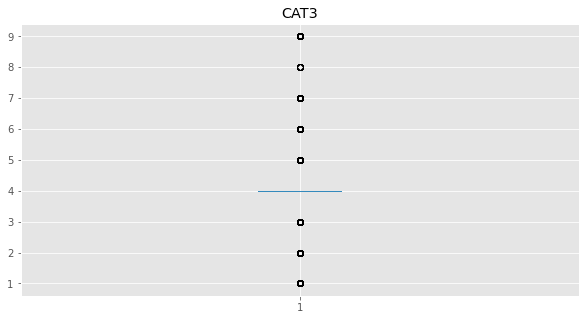

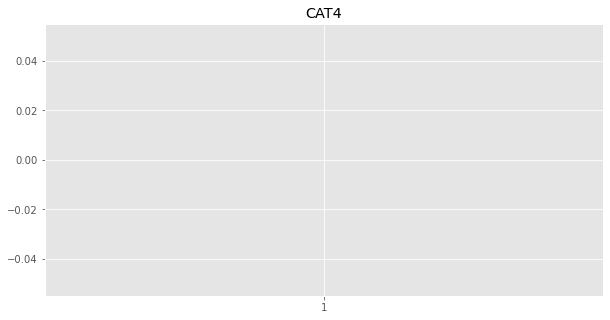

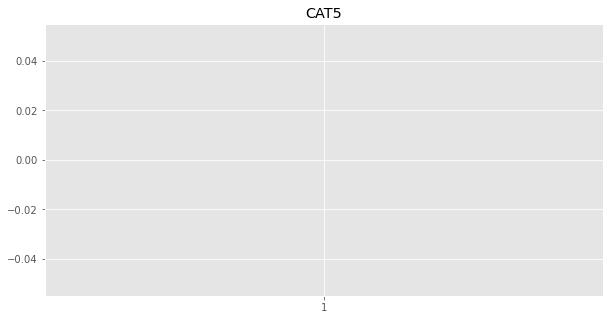

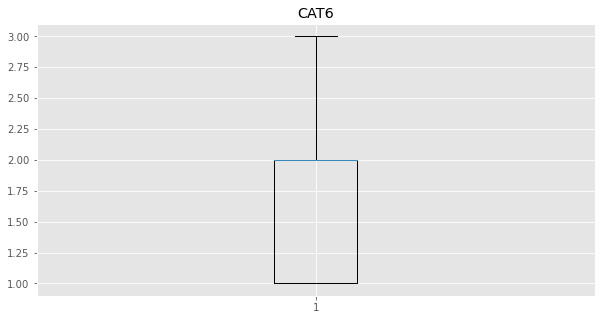

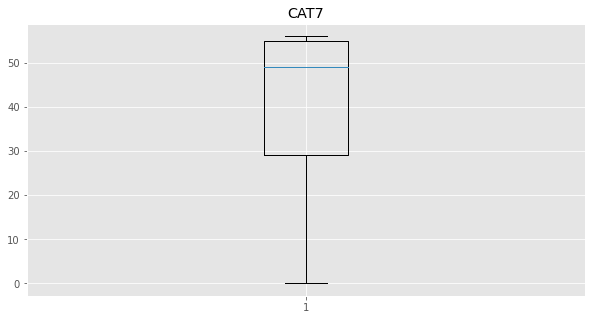

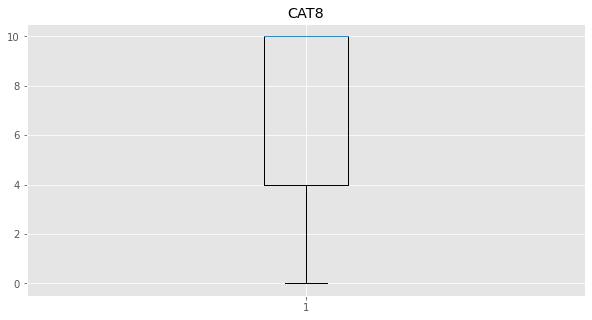

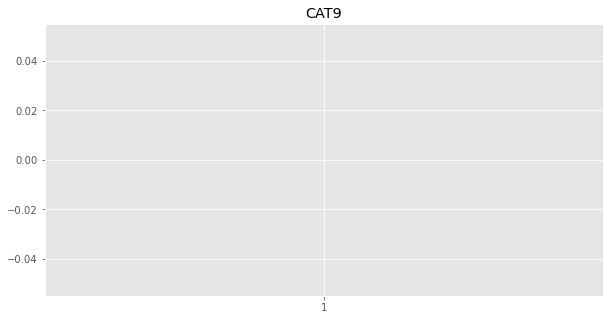

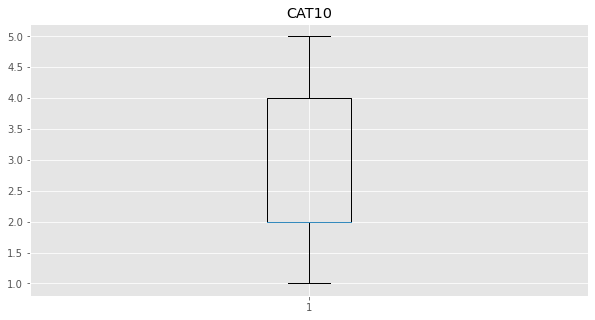

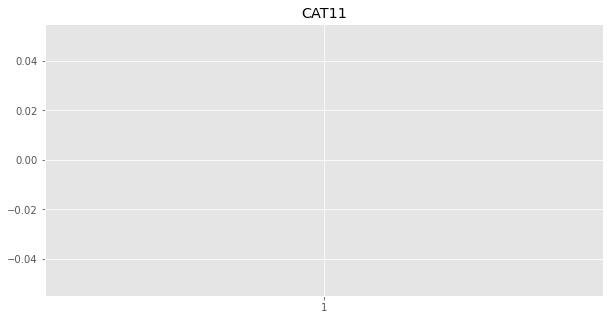

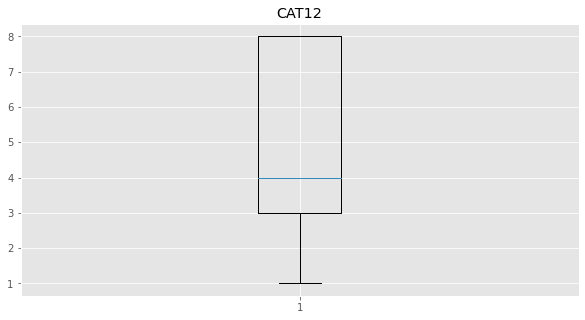

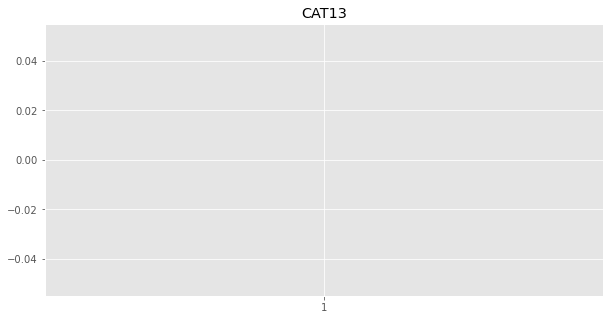

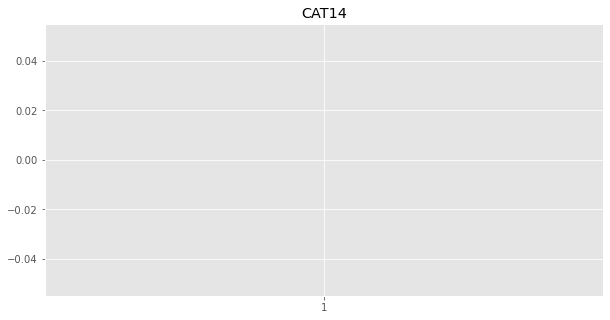

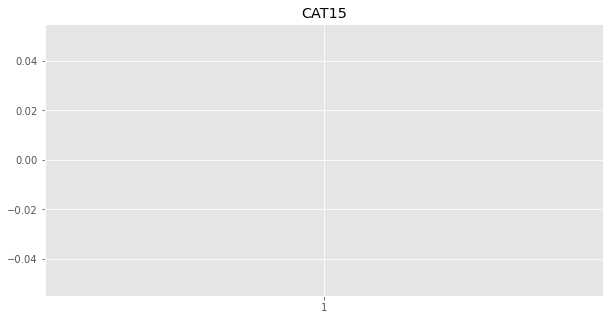

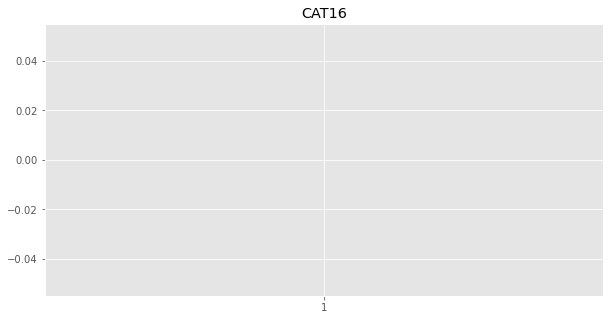

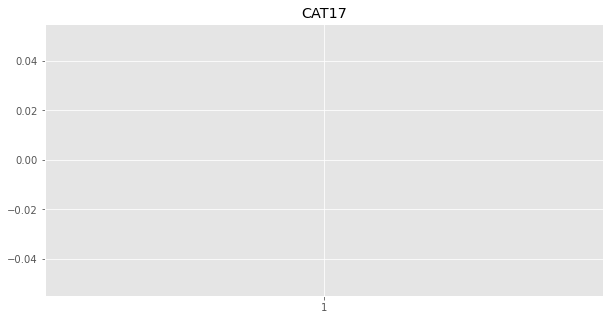

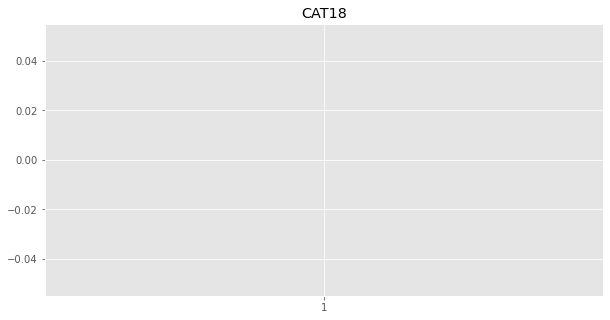

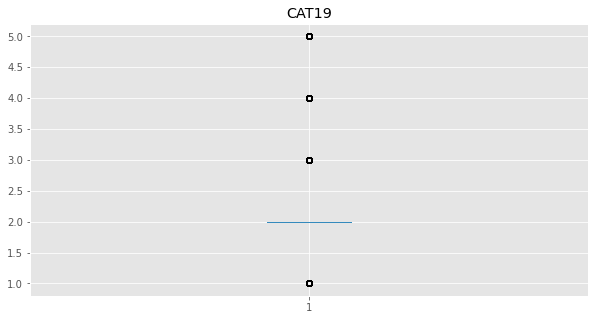

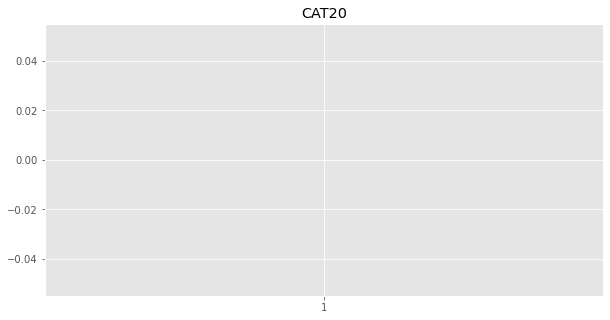

In [27]:
plt.figure(figsize=(10, 5))
plt.boxplot(df["cat1"])
plt.title('CAT1')
plt.figure(figsize=(10, 5))
plt.boxplot(df['cat2'])
plt.title('CAT2')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat3'])
plt.title('CAT3')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat4'])
plt.title('CAT4')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat5'])
plt.title('CAT5')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat6'])
plt.title('CAT6')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat7'])
plt.title('CAT7')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat8'])
plt.title('CAT8')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat9'])
plt.title('CAT9')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat10'])
plt.title('CAT10')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat11'])
plt.title('CAT11')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat12'])
plt.title('CAT12')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat13'])
plt.title('CAT13')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat14'])
plt.title('CAT14')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat15'])
plt.title('CAT15')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat16'])
plt.title('CAT16')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat17'])
plt.title('CAT17')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat18'])
plt.title('CAT18')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat19'])
plt.title('CAT19')


plt.figure(figsize=(10, 5))
plt.boxplot(df['cat20'])
plt.title('CAT20')



GROUPED BOX PLOTS

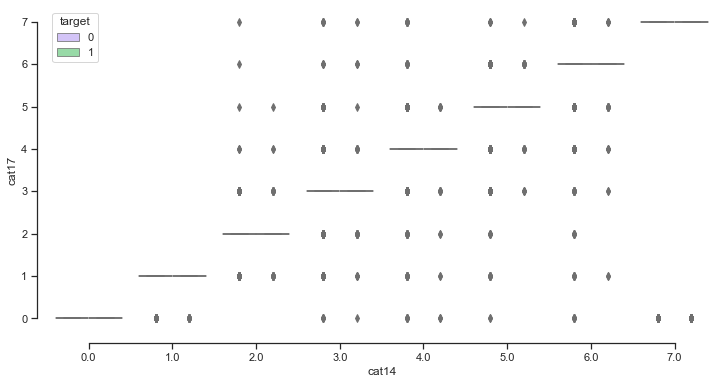

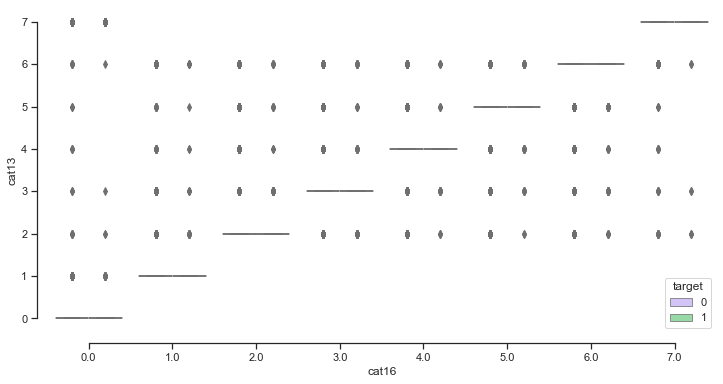

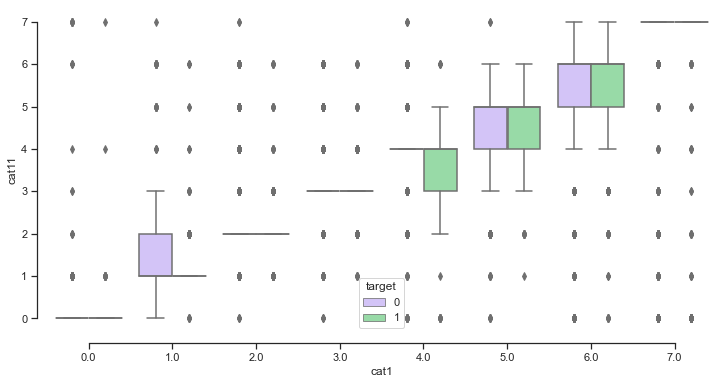

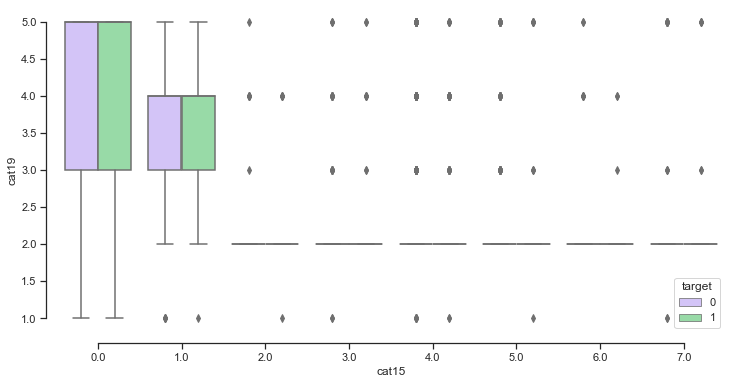

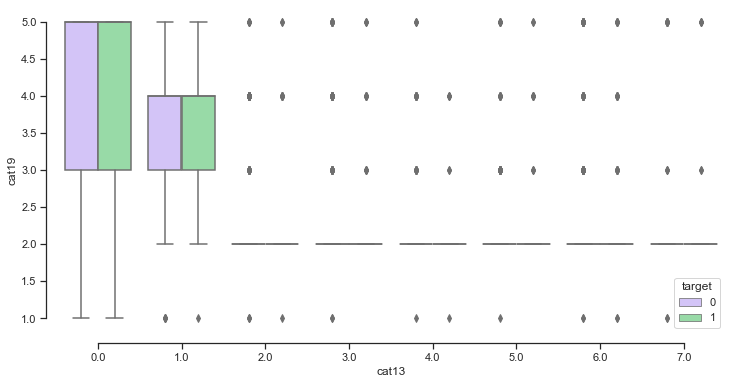

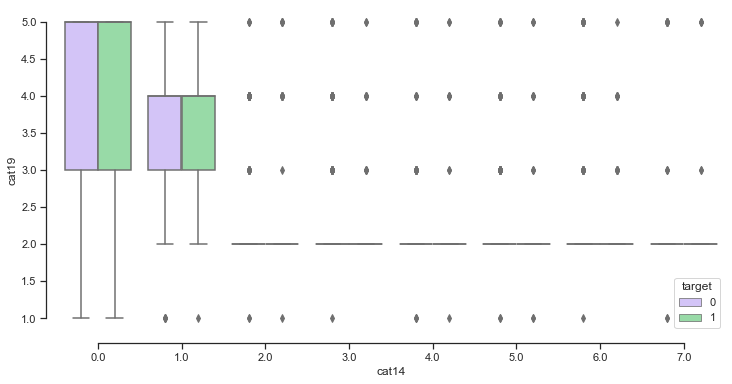

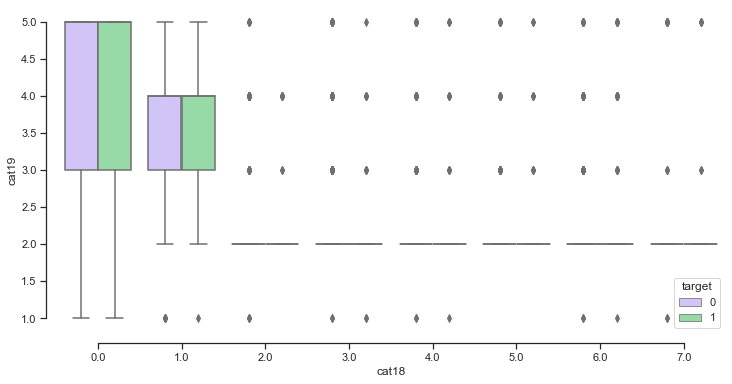

In [28]:
#STRONG CORRELATION
#positively correlated, corrletation: 0.95
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat14, y=df.cat17,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()


#positively correlated, corrletation: 0.92
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat16, y=df.cat13,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()

#positively correlated, corrletation: 0.85
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat1, y=df.cat11,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()


#negatively correlated, corrletation: -0.55
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat15, y=df.cat19,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()

#negatively correlated, corrletation: -0.53
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat13, y=df.cat19,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()

#negatively correlated, corrletation: -0.53
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat14, y=df.cat19,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()

#negatively correlated, corrletation: -0.53
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat18, y=df.cat19,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()

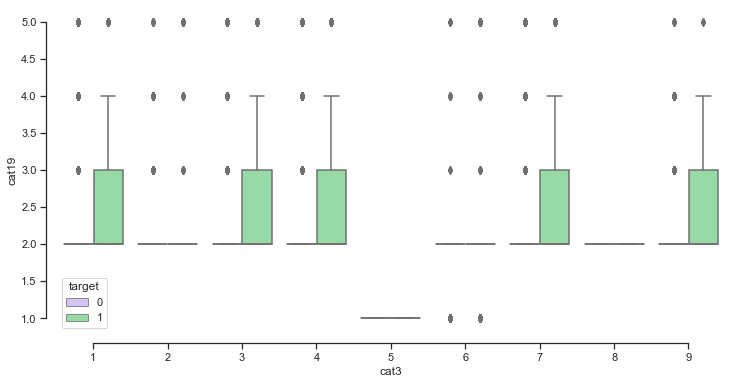

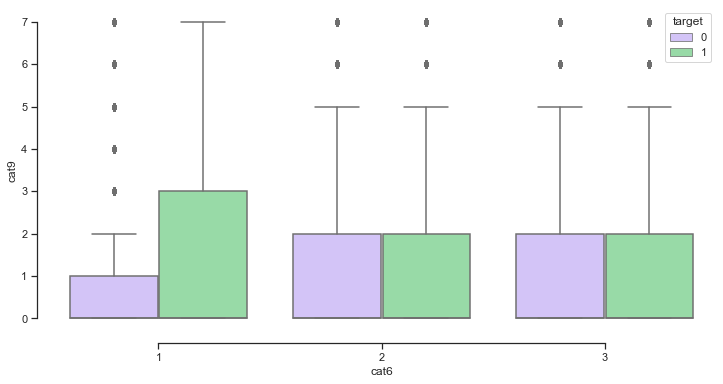

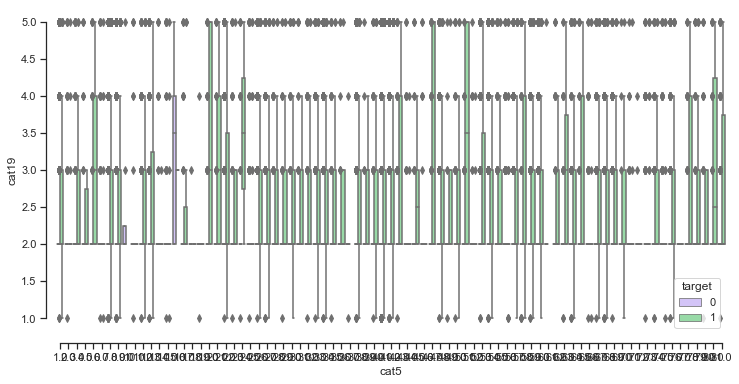

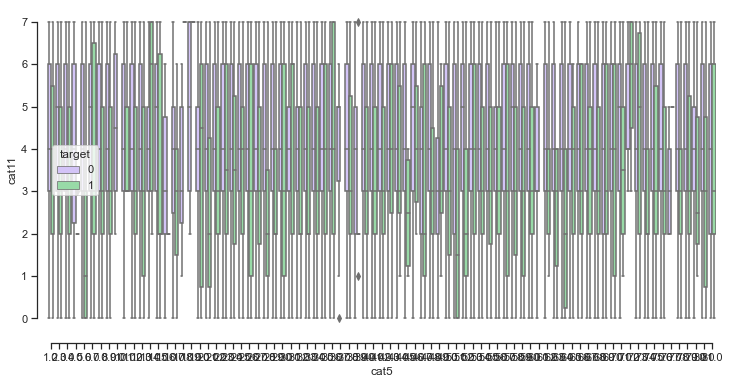

In [29]:
#very low correlated, corrletation: -0.0013
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat3, y=df.cat19,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()




#very low correlated, corrletation: -0.0024
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat6, y=df.cat9,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()






#very low correlated, corrletation: -0.0009
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat5, y=df.cat19,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()





#very low correlated, corrletation: -0.00098
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat5, y=df.cat11,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()



NUMERICAL VARIABLES

HISTOGRAMS

In [30]:
#define a function to get histogram of each column
def plot_histo(cstr, column):
    plt.hist(column)
    plt.title(cstr)
    plt.xlabel('Value')
    plt.ylabel('Frequency')
    plt.show()  
    
    # Add title and axis names


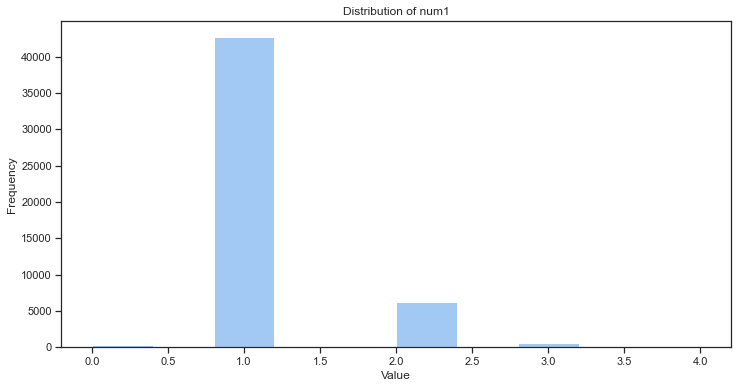

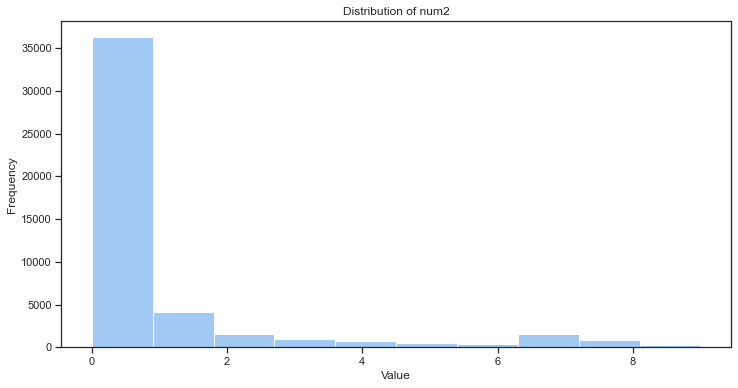

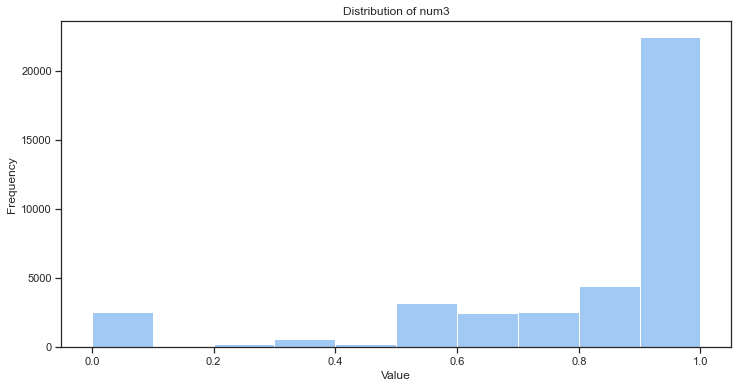

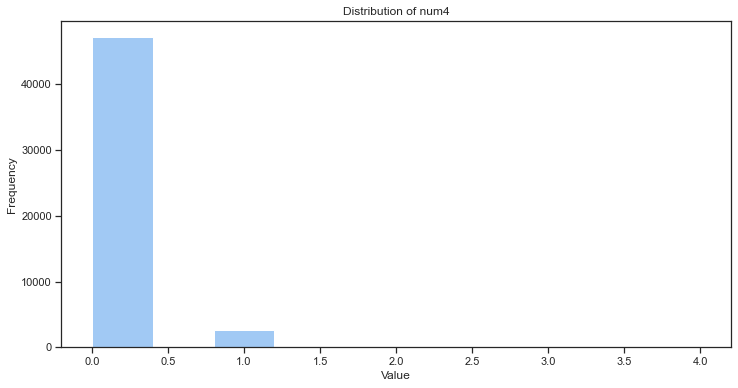

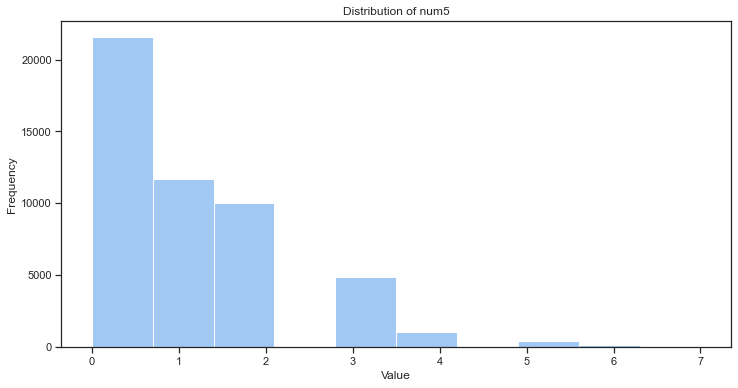

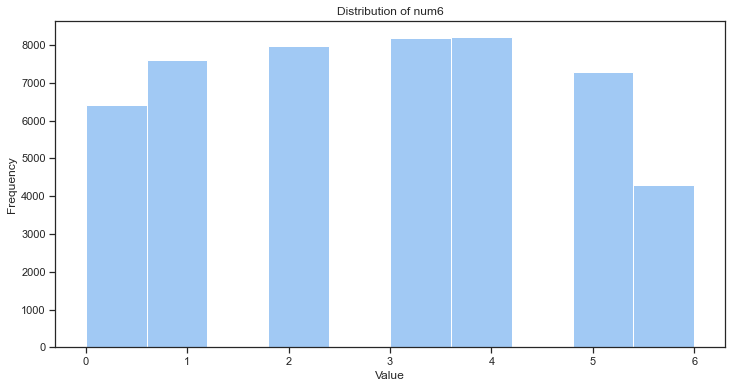

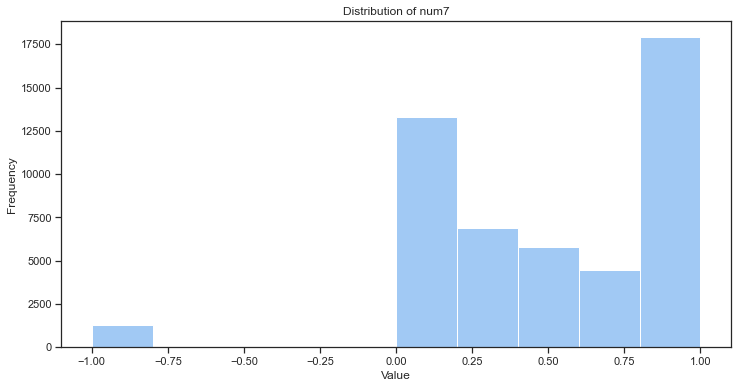

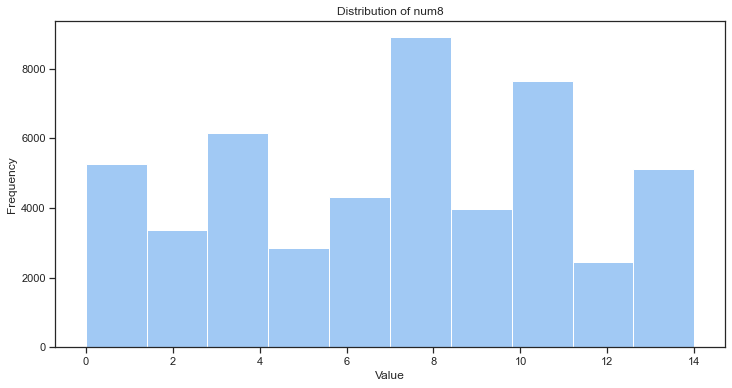

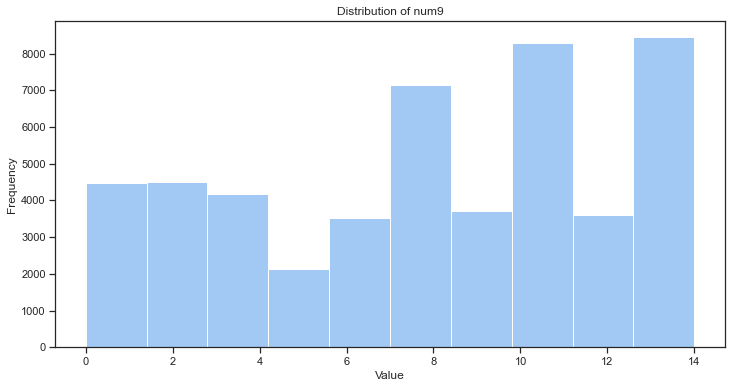

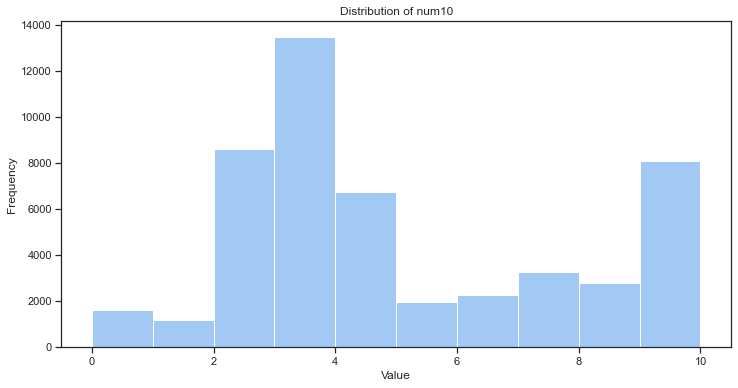

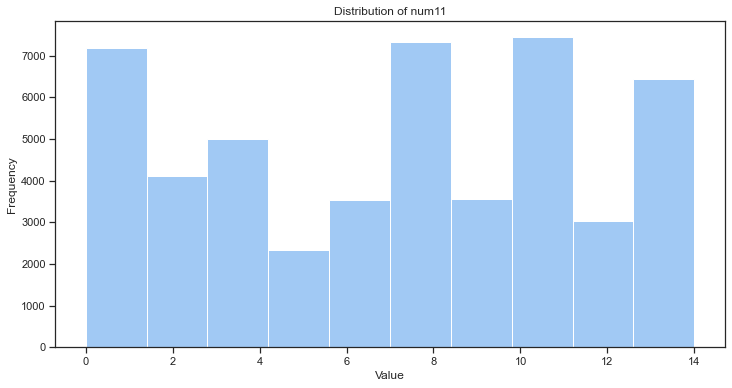

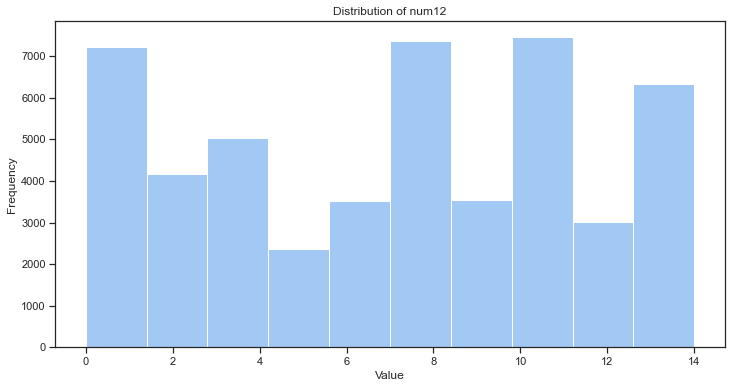

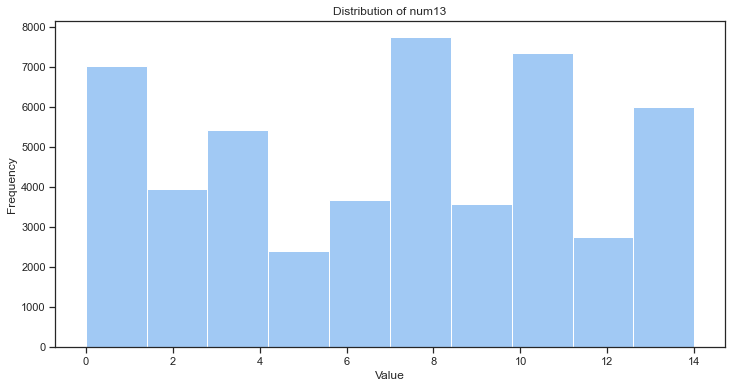

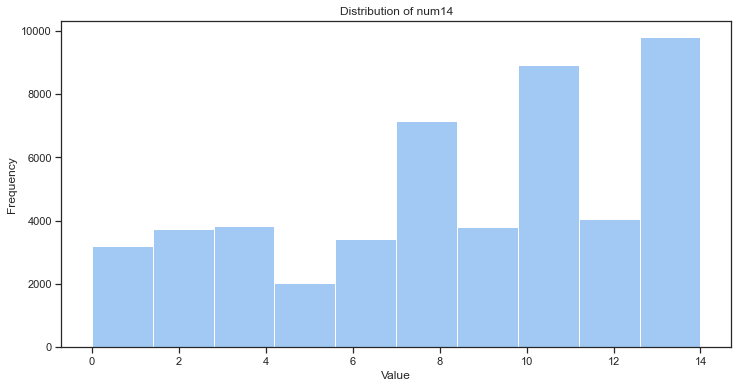

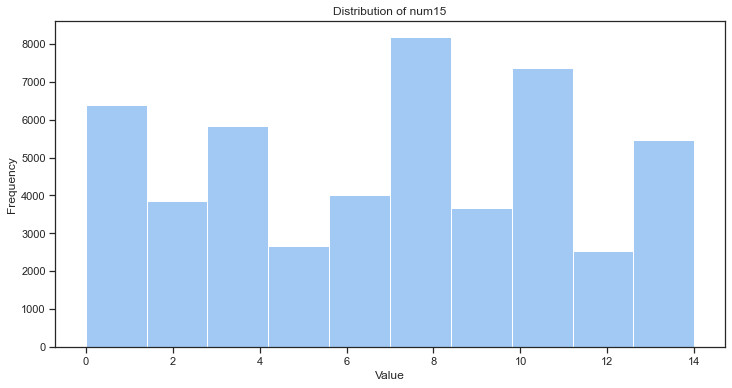

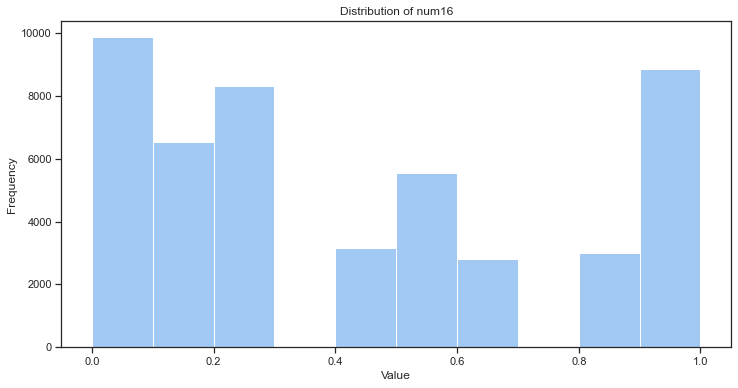

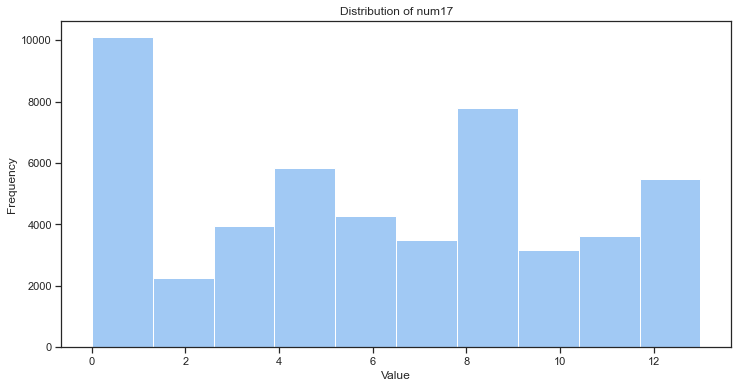

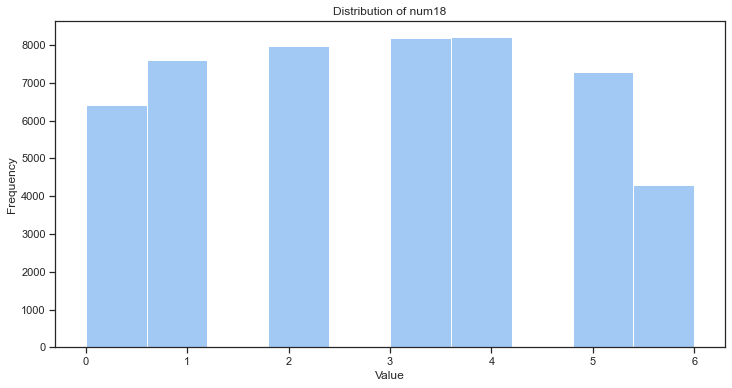

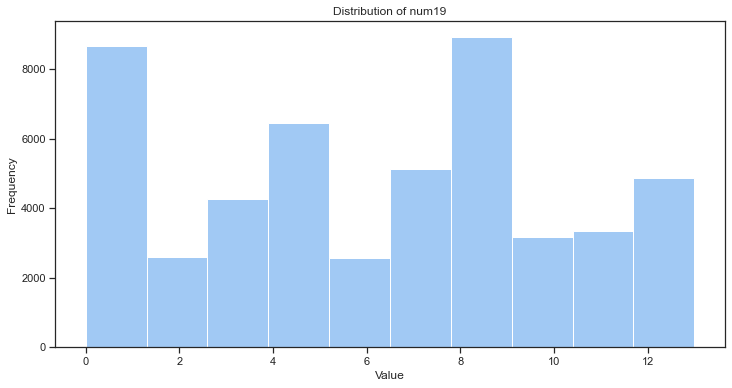

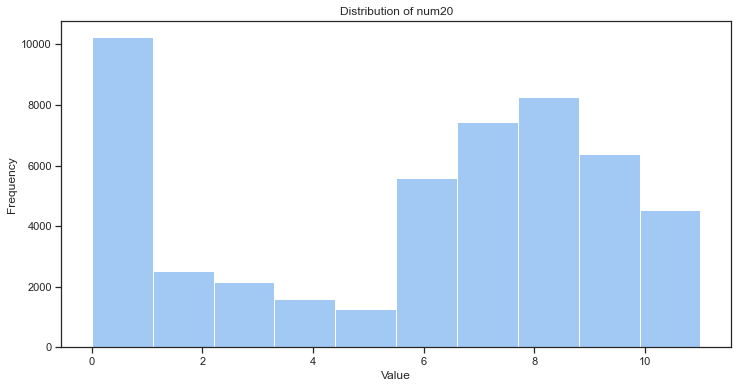

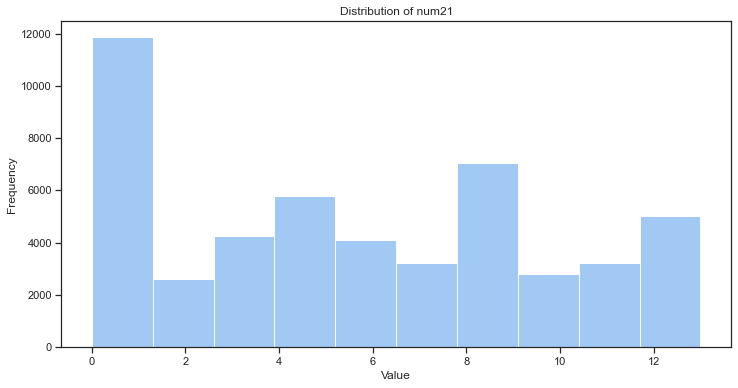

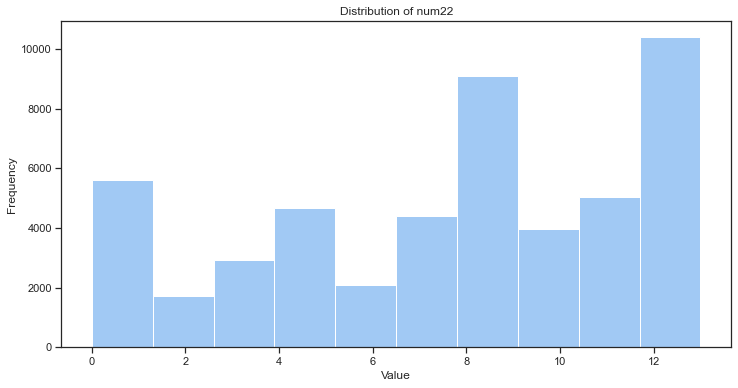

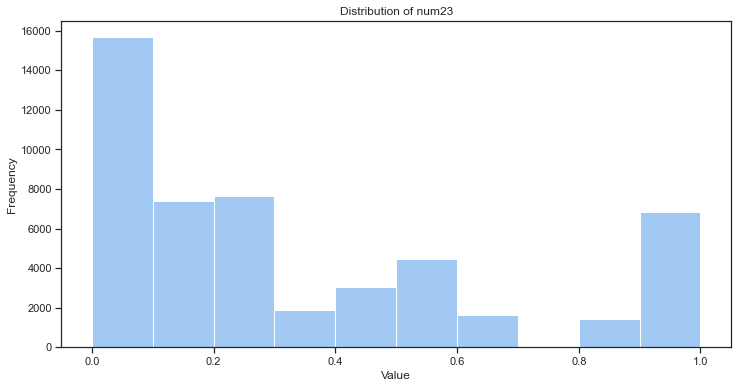

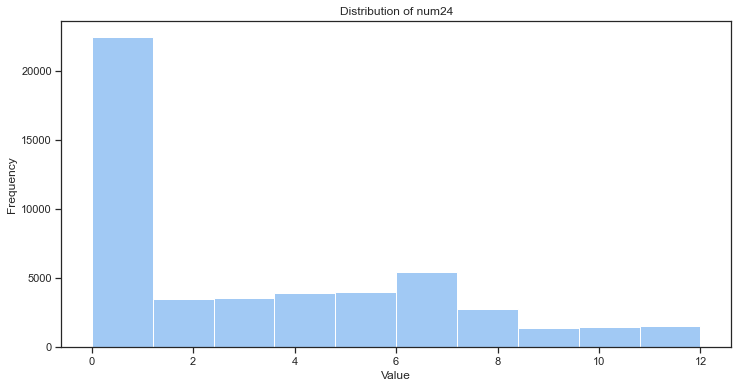

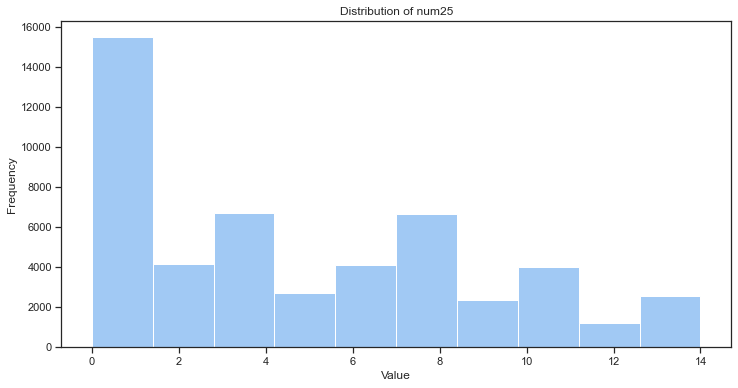

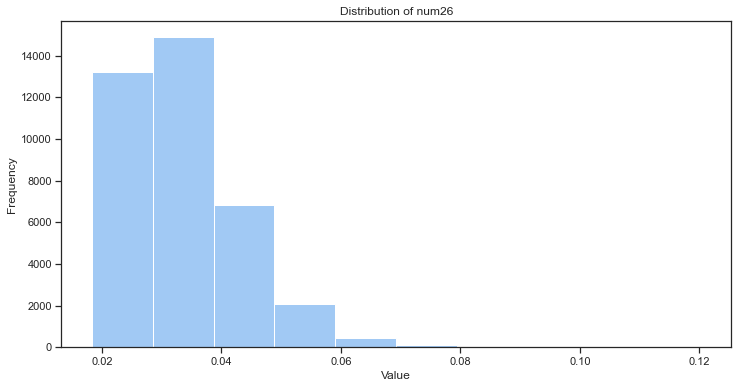

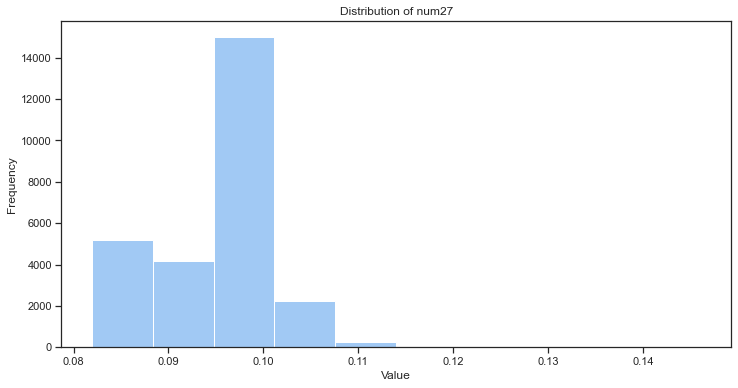

In [31]:
#numeric variables
#histo plot for numeric variables
df.num1.describe()
plot_histo("Distribution of num1", df.num1)

df.num2.describe()
plot_histo("Distribution of num2", df.num2)

df.num3.describe()
plot_histo("Distribution of num3", df.num3)

df.num4.describe()
plot_histo("Distribution of num4", df.num4)

df.num5.describe()
plot_histo("Distribution of num5", df.num5)

df.num6.describe()
plot_histo("Distribution of num6", df.num6)

df.num7.describe()
plot_histo("Distribution of num7", df.num7)

df.num8.describe()
plot_histo("Distribution of num8", df.num8)

df.num9.describe()
plot_histo("Distribution of num9", df.num9)

df.num10.describe()
plot_histo("Distribution of num10", df.num10)

df.num11.describe()
plot_histo("Distribution of num11", df.num11)

df.num12.describe()
plot_histo("Distribution of num12", df.num12)

df.num13.describe()
plot_histo("Distribution of num13", df.num13)

df.num14.describe()
plot_histo("Distribution of num14", df.num14)

df.num15.describe()
plot_histo("Distribution of num15", df.num15)

df.num16.describe()
plot_histo("Distribution of num16", df.num16)

df.num17.describe()
plot_histo("Distribution of num17", df.num17)

df.num18.describe()
plot_histo("Distribution of num18", df.num18)

df.num19.describe()
plot_histo("Distribution of num19", df.num19)

df.num20.describe()
plot_histo("Distribution of num20", df.num20)

df.num21.describe()
plot_histo("Distribution of num21", df.num21)

df.num22.describe()
plot_histo("Distribution of num22", df.num22)

df.num23.describe()
plot_histo("Distribution of num23", df.num23)

df.num24.describe()
plot_histo("Distribution of num24", df.num24)

df.num25.describe()
plot_histo("Distribution of num25", df.num25)

df.num26.describe()
plot_histo("Distribution of num26", df.num26)

df.num27.describe()
plot_histo("Distribution of num27", df.num27)


HEAT MAP FOR NUMERIC VARIABLES

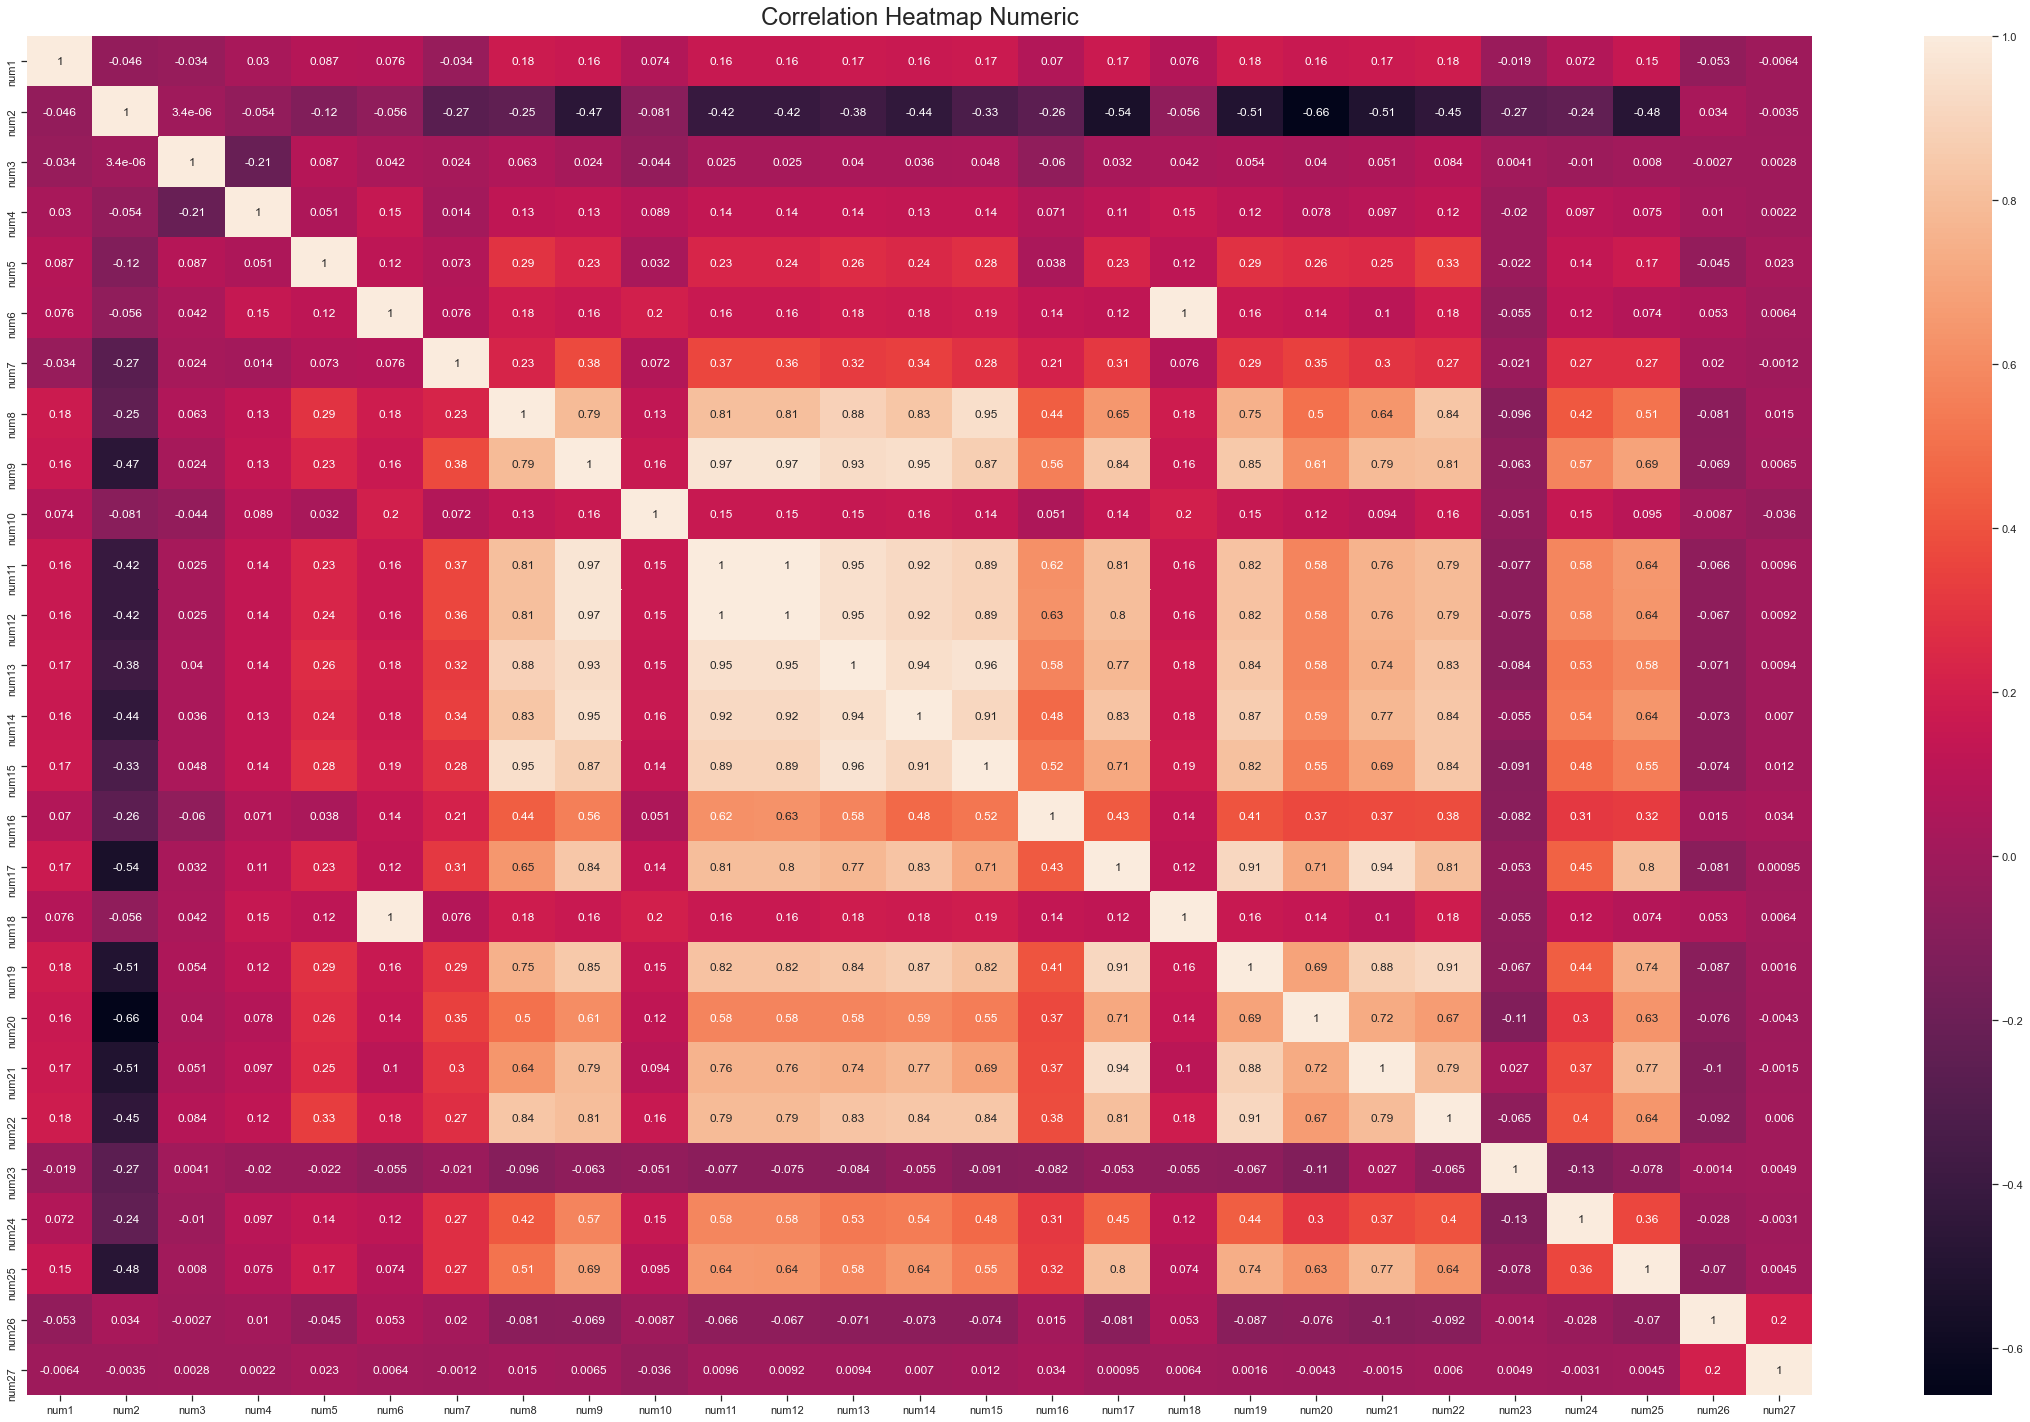

In [32]:
#heat map only for numeric variables
data_num = df.iloc[:,20:47]
plt.figure(figsize=(40, 25))
heatmap=sns.heatmap(data_num.corr(), annot=True,yticklabels=data_num.columns,xticklabels=data_num.columns)
heatmap.set_title('Correlation Heatmap Numeric', fontdict={'fontsize':24}, pad=12);

BOX PLOT FOR NUMERIC VARIABLES

<ipython-input-33-bd0a124ff644>:81: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  plt.figure(figsize=(10, 5))


Text(0.5, 1.0, 'TARGET')

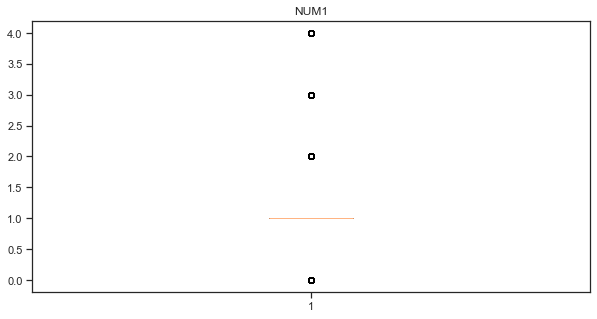

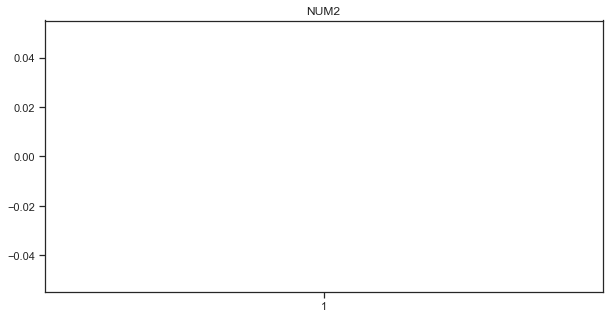

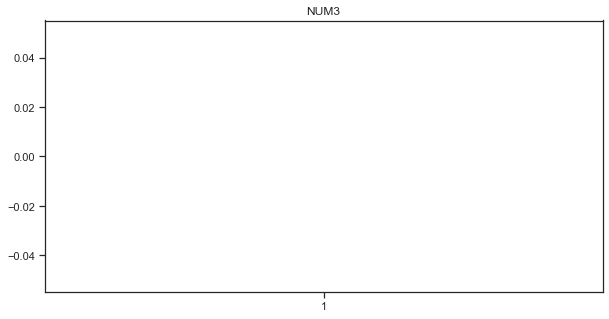

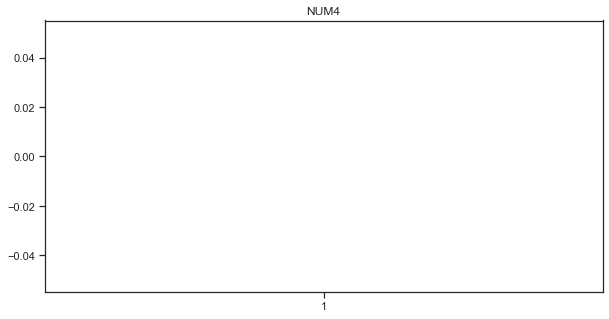

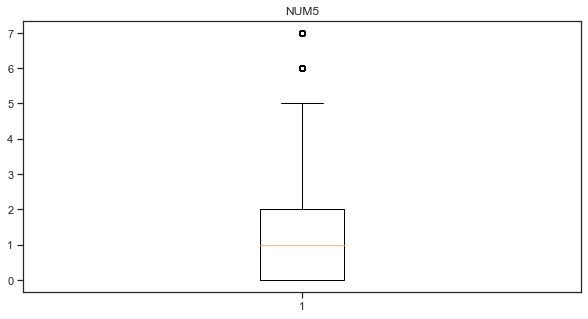

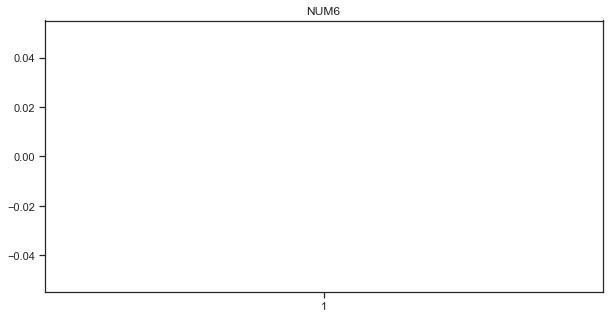

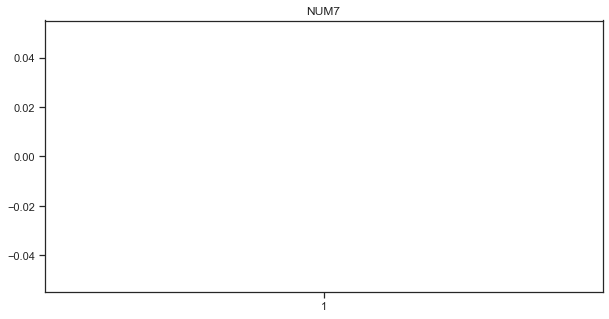

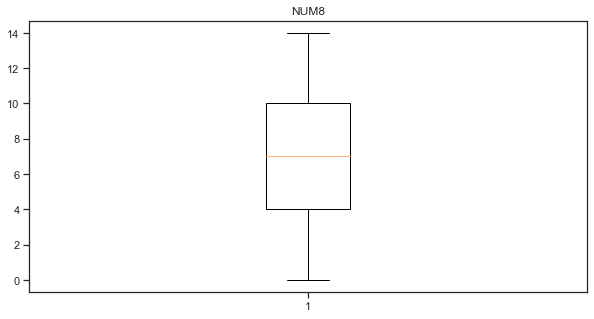

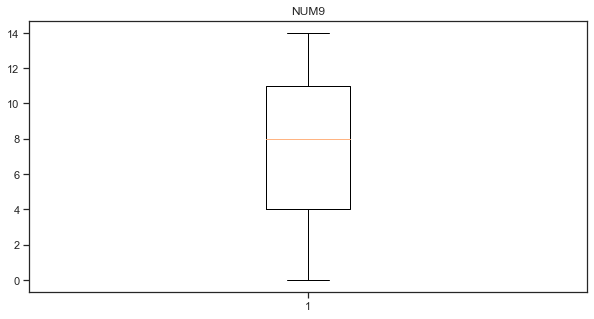

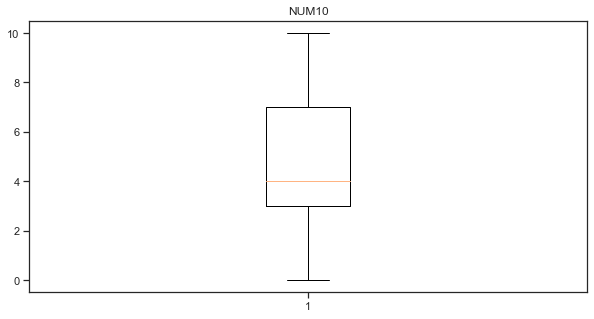

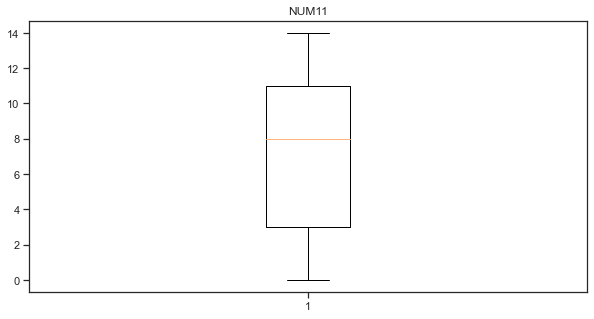

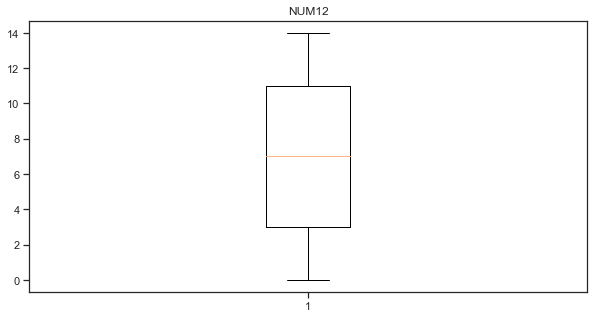

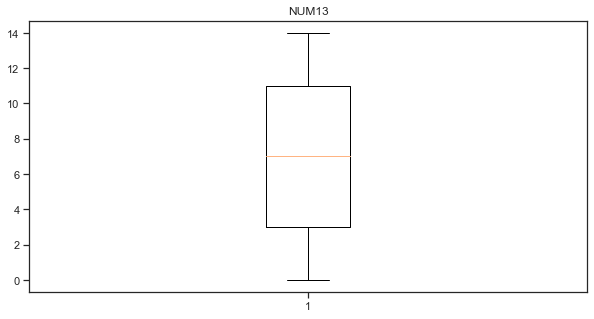

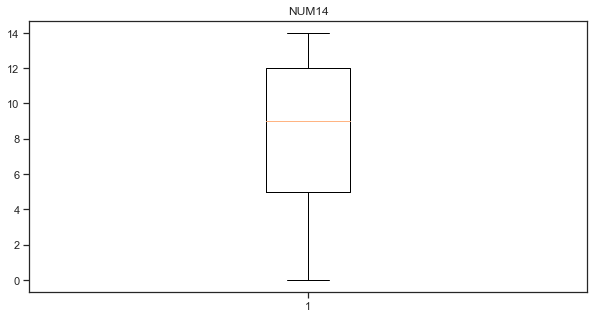

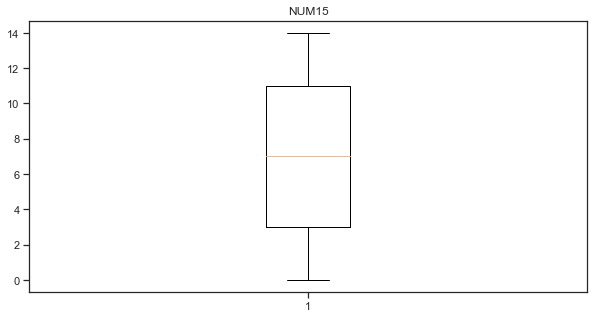

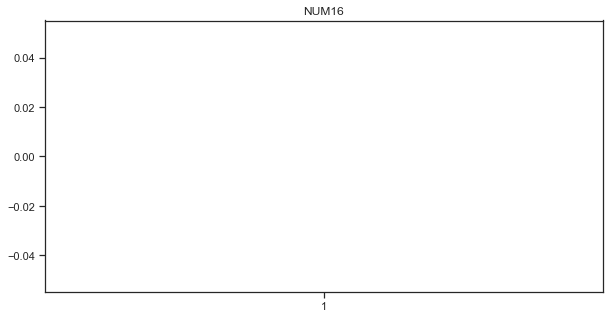

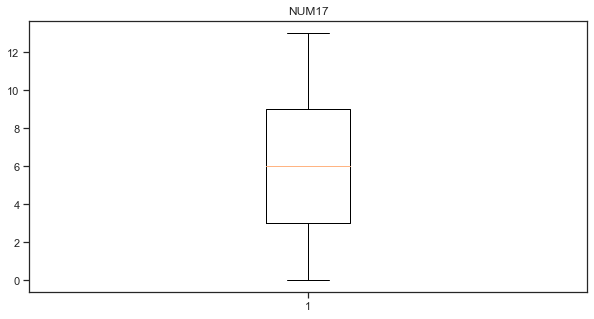

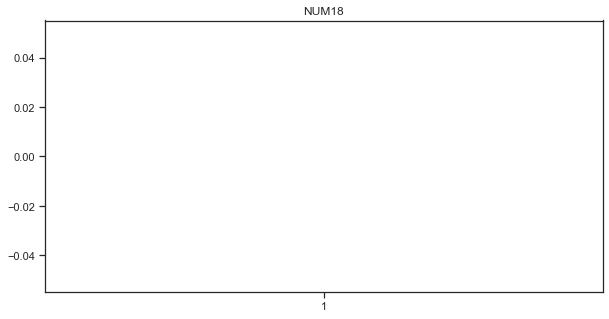

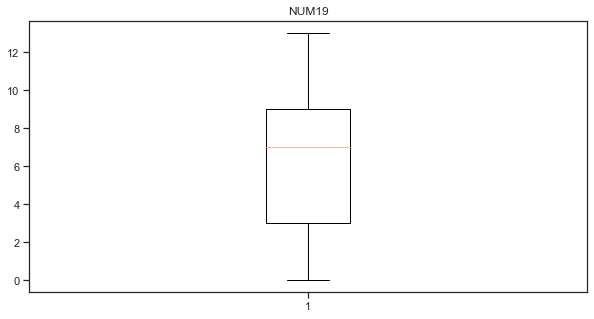

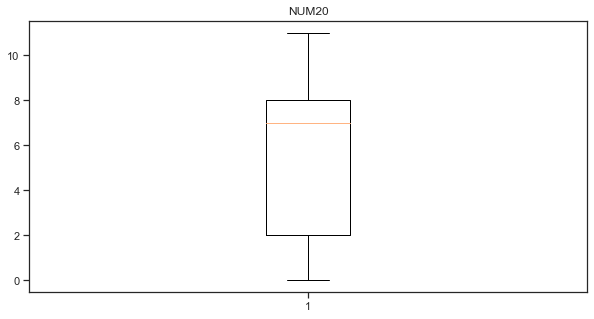

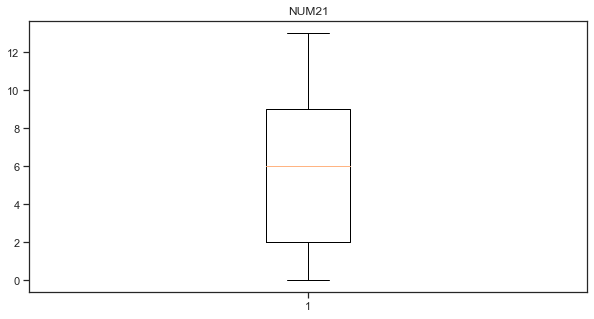

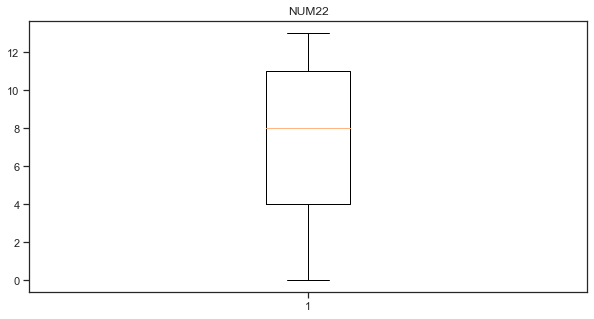

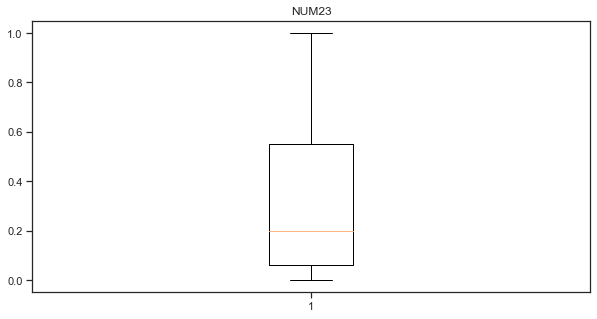

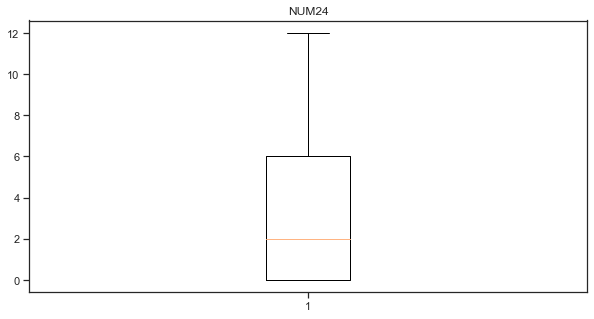

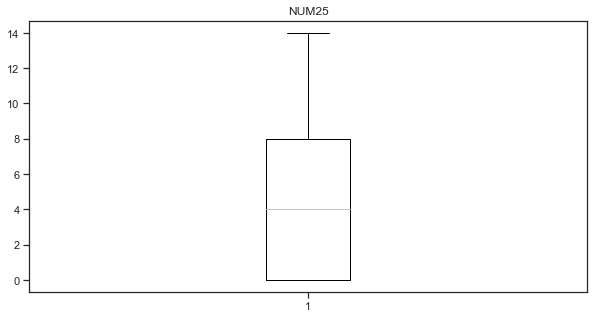

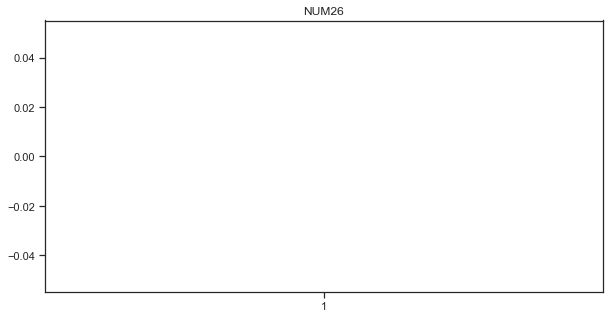

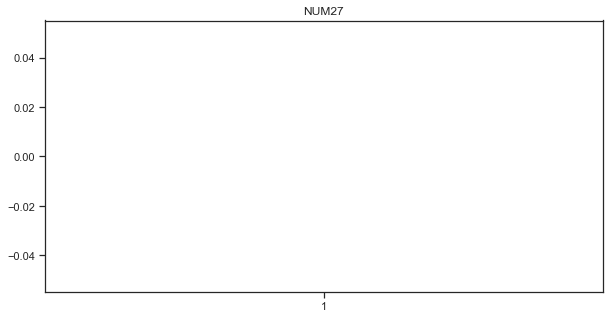

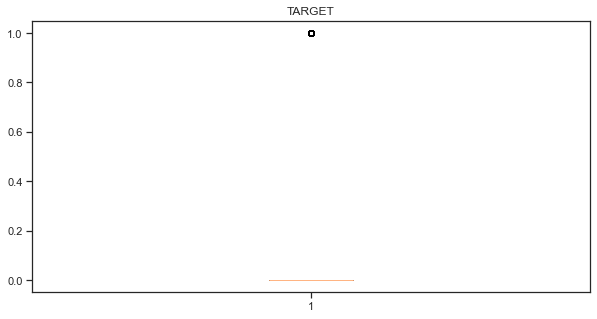

In [33]:


plt.figure(figsize=(10, 5))
plt.boxplot(df['num1'])
plt.title('NUM1')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num2'])
plt.title('NUM2')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num3'])
plt.title('NUM3')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num4'])
plt.title('NUM4')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num5'])
plt.title('NUM5')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num6'])
plt.title('NUM6')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num7'])
plt.title('NUM7')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num8'])
plt.title('NUM8')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num9'])
plt.title('NUM9')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num10'])
plt.title('NUM10')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num11'])
plt.title('NUM11')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num12'])
plt.title('NUM12')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num13'])
plt.title('NUM13')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num14'])
plt.title('NUM14')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num15'])
plt.title('NUM15')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num16'])
plt.title('NUM16')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num17'])
plt.title('NUM17')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num18'])
plt.title('NUM18')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num19'])
plt.title('NUM19')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num20'])
plt.title('NUM20')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num21'])
plt.title('NUM21')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num22'])
plt.title('NUM22')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num23'])
plt.title('NUM23')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num24'])
plt.title('NUM24')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num25'])
plt.title('NUM25')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num26'])
plt.title('NUM26')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num27'])
plt.title('NUM27')

plt.figure(figsize=(10, 5))
plt.boxplot(df['target'])
plt.title('TARGET')





SCATTERPLOT FOR NUMERIC X NUMERIC

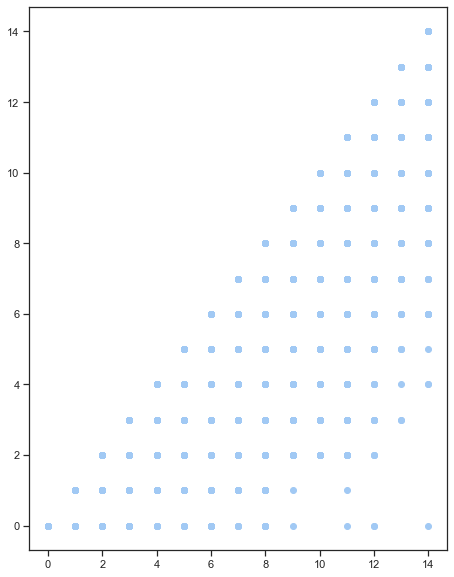

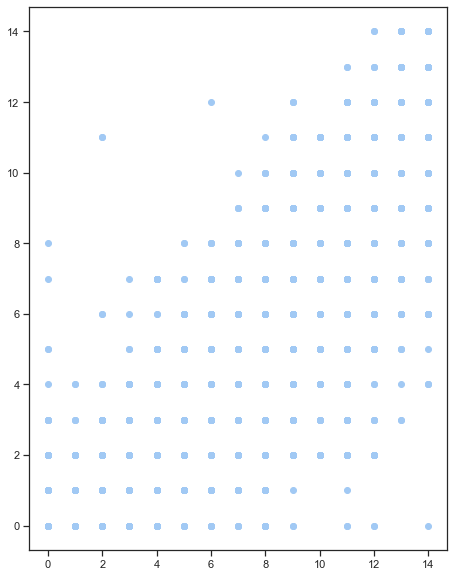

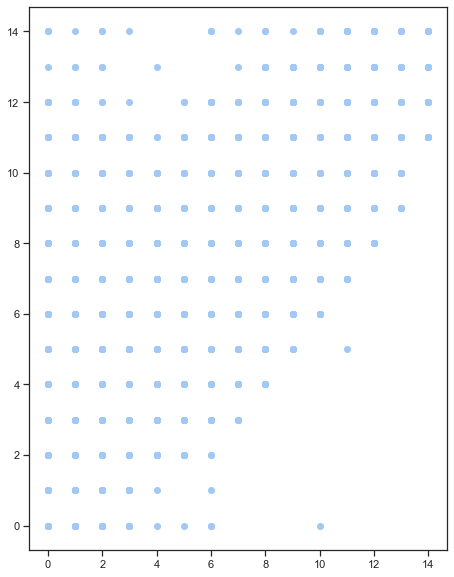

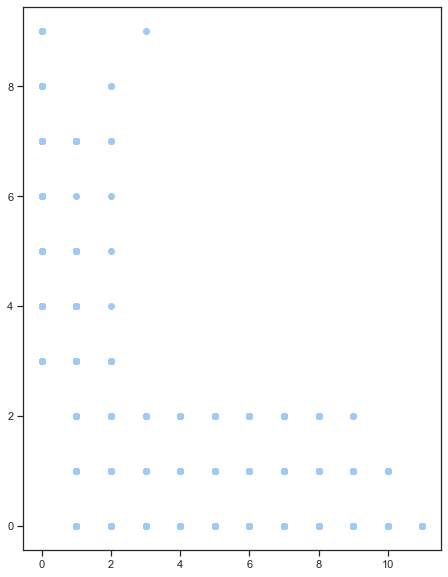

In [66]:
#for variables with strong correlation (close to 1 in absolute value)
plt.scatter(data_num['num9'], data_num['num11'])
plt.show()
#CORRELASYON 0.97

plt.scatter(data_num['num9'], data_num['num12'])
plt.show()
#CORRELASYON 0.97

plt.scatter(data_num['num11'], data_num['num13'])
plt.show()
#CORRELASYON 0.95

plt.scatter(data_num['num20'], data_num['num2'])
plt.show()
#CORRELASYON -0.66

plt.scatter(data_num['num25'], data_num['num2'])
plt.show()
#CORRELASYON -0.48

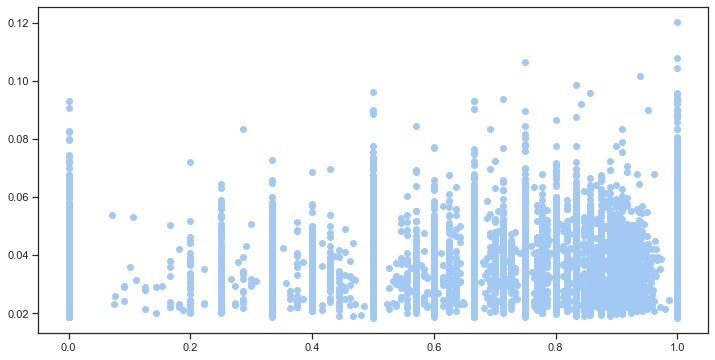

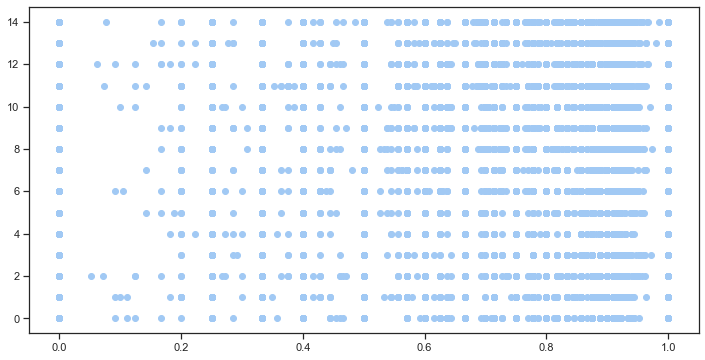

In [35]:
#for variables with weak correlation (close to 0 in absolute value)
plt.scatter(data_num['num3'], data_num['num26'])
plt.show()
#CORRELASYON -0.0027

plt.scatter(data_num['num3'], data_num['num13'])
plt.show()
#CORRELASYON 0.04

plt.scatter(data_num['num10'], data_num['num27'])
plt.show()
#CORRELASYON 0.036

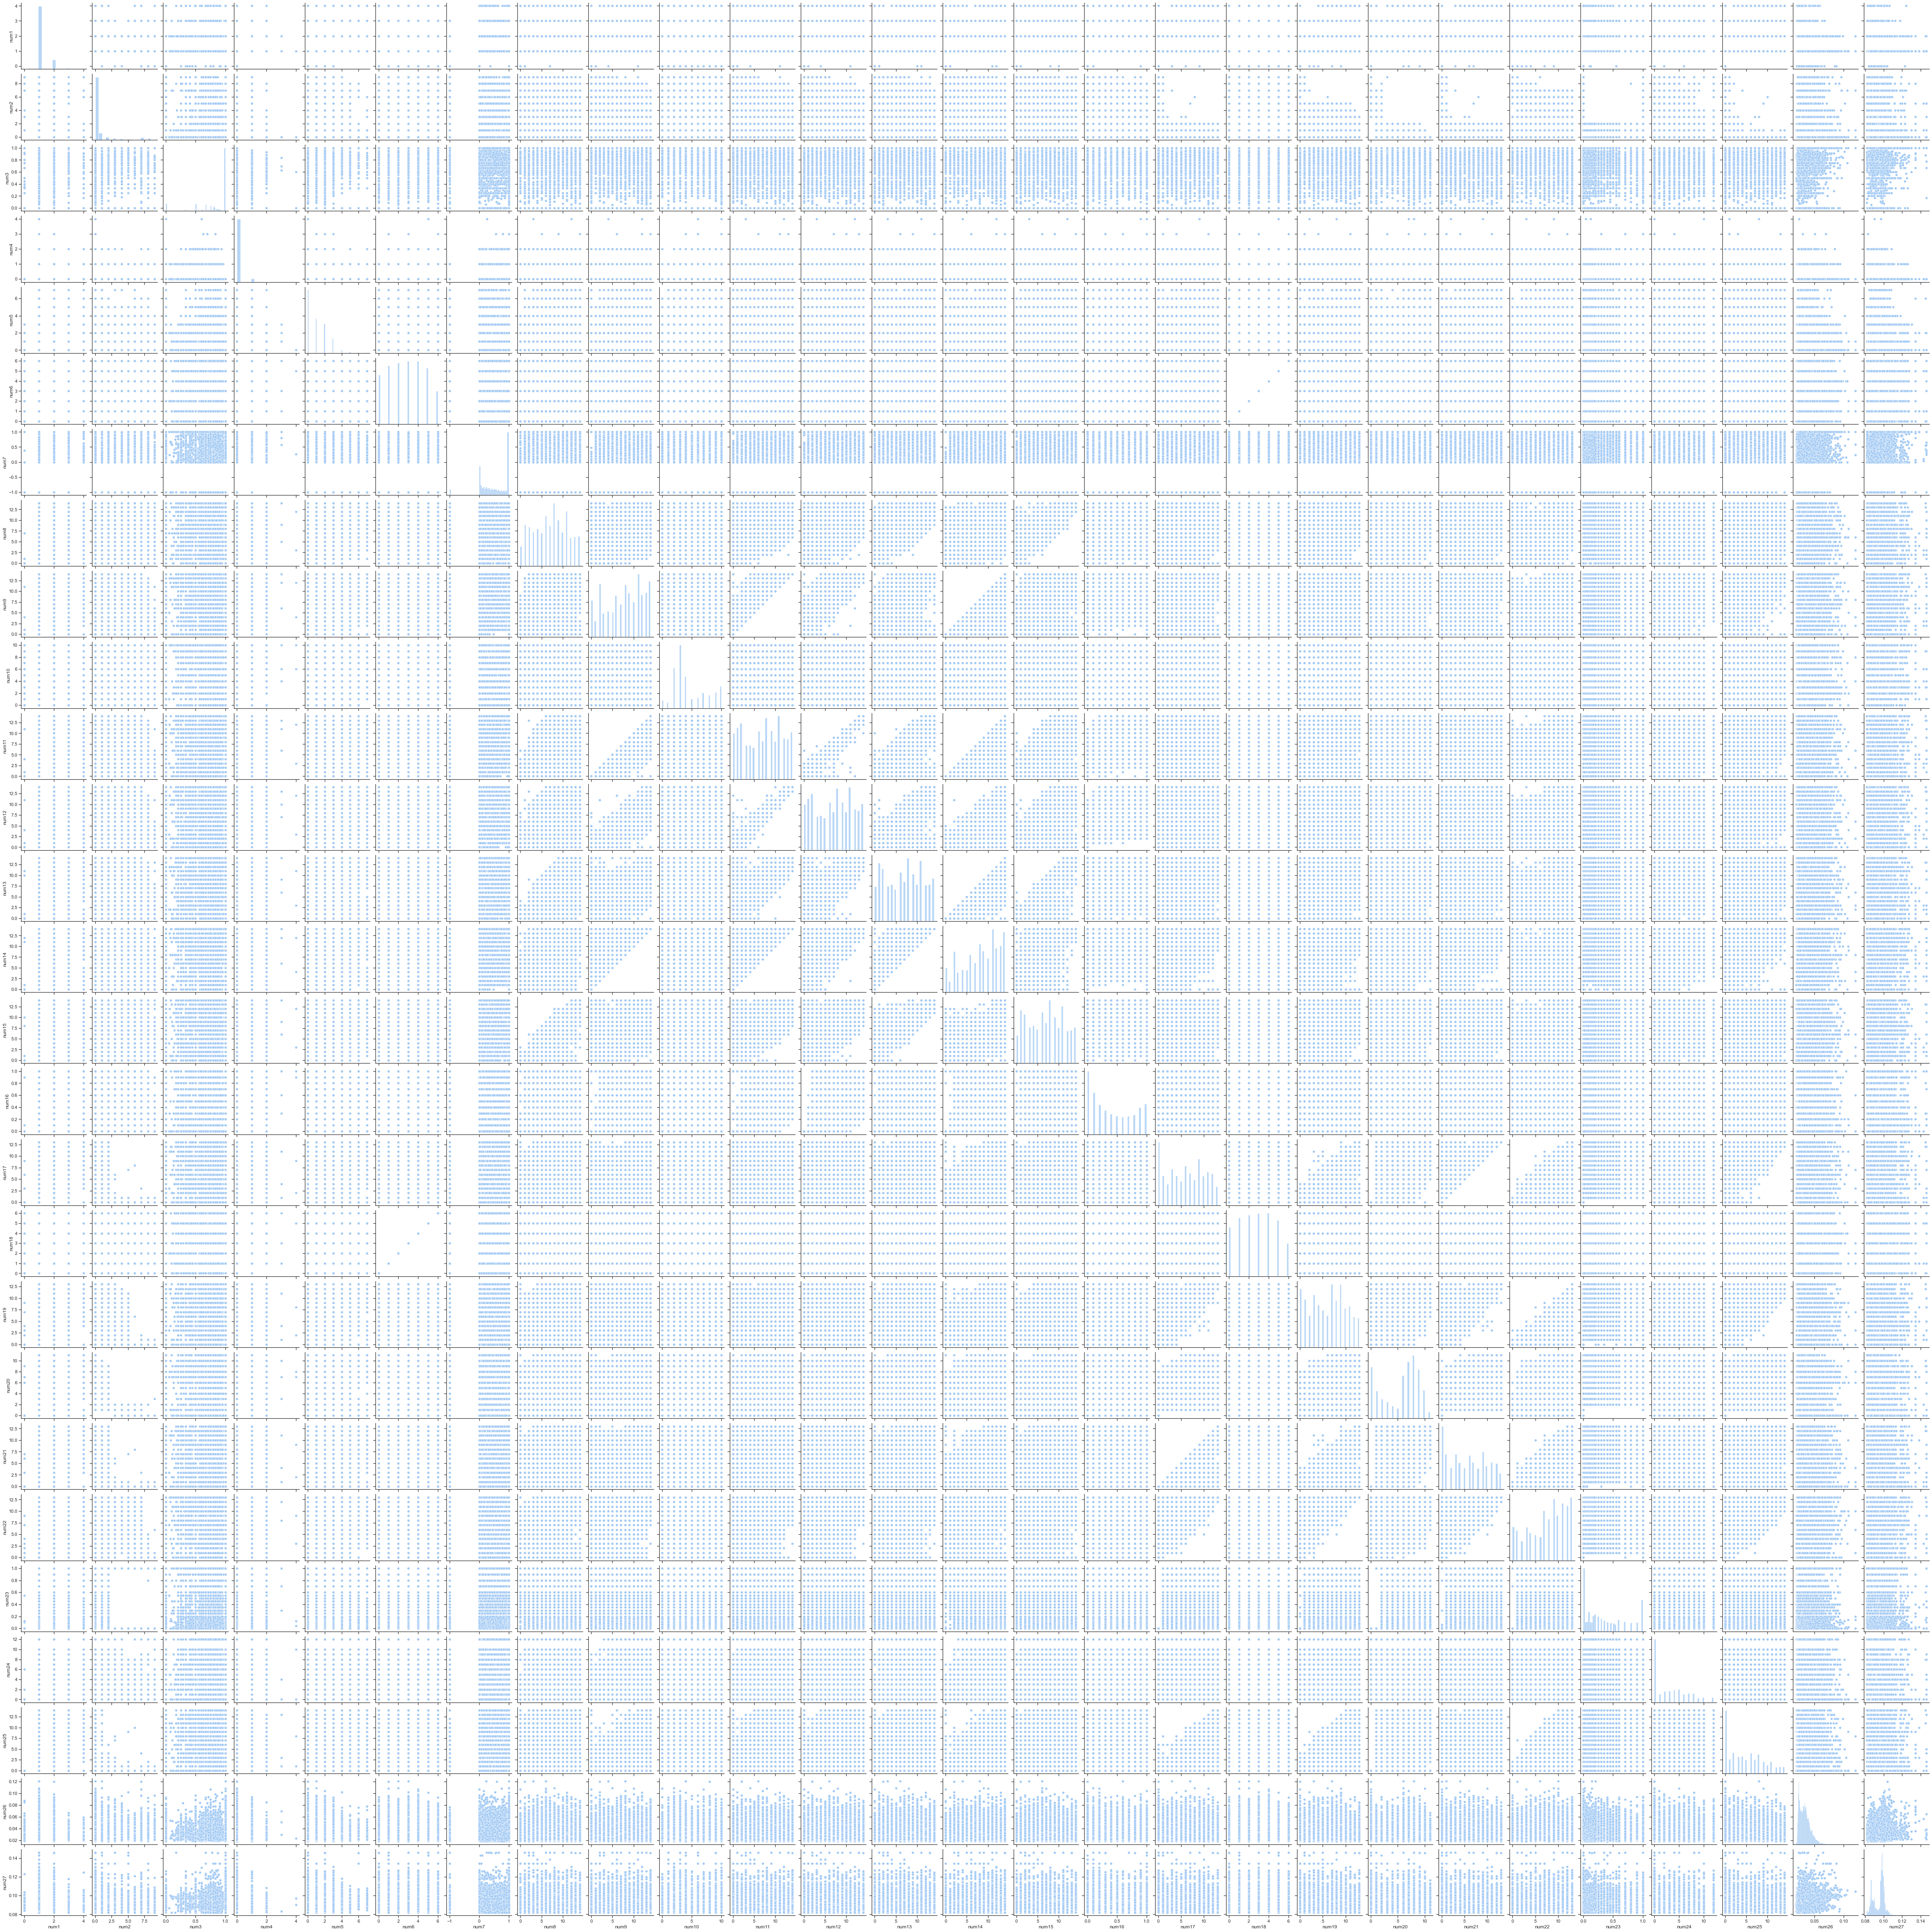

In [36]:
sns.pairplot(data_num)

HEAT MAP FOR ALL VARIABLES

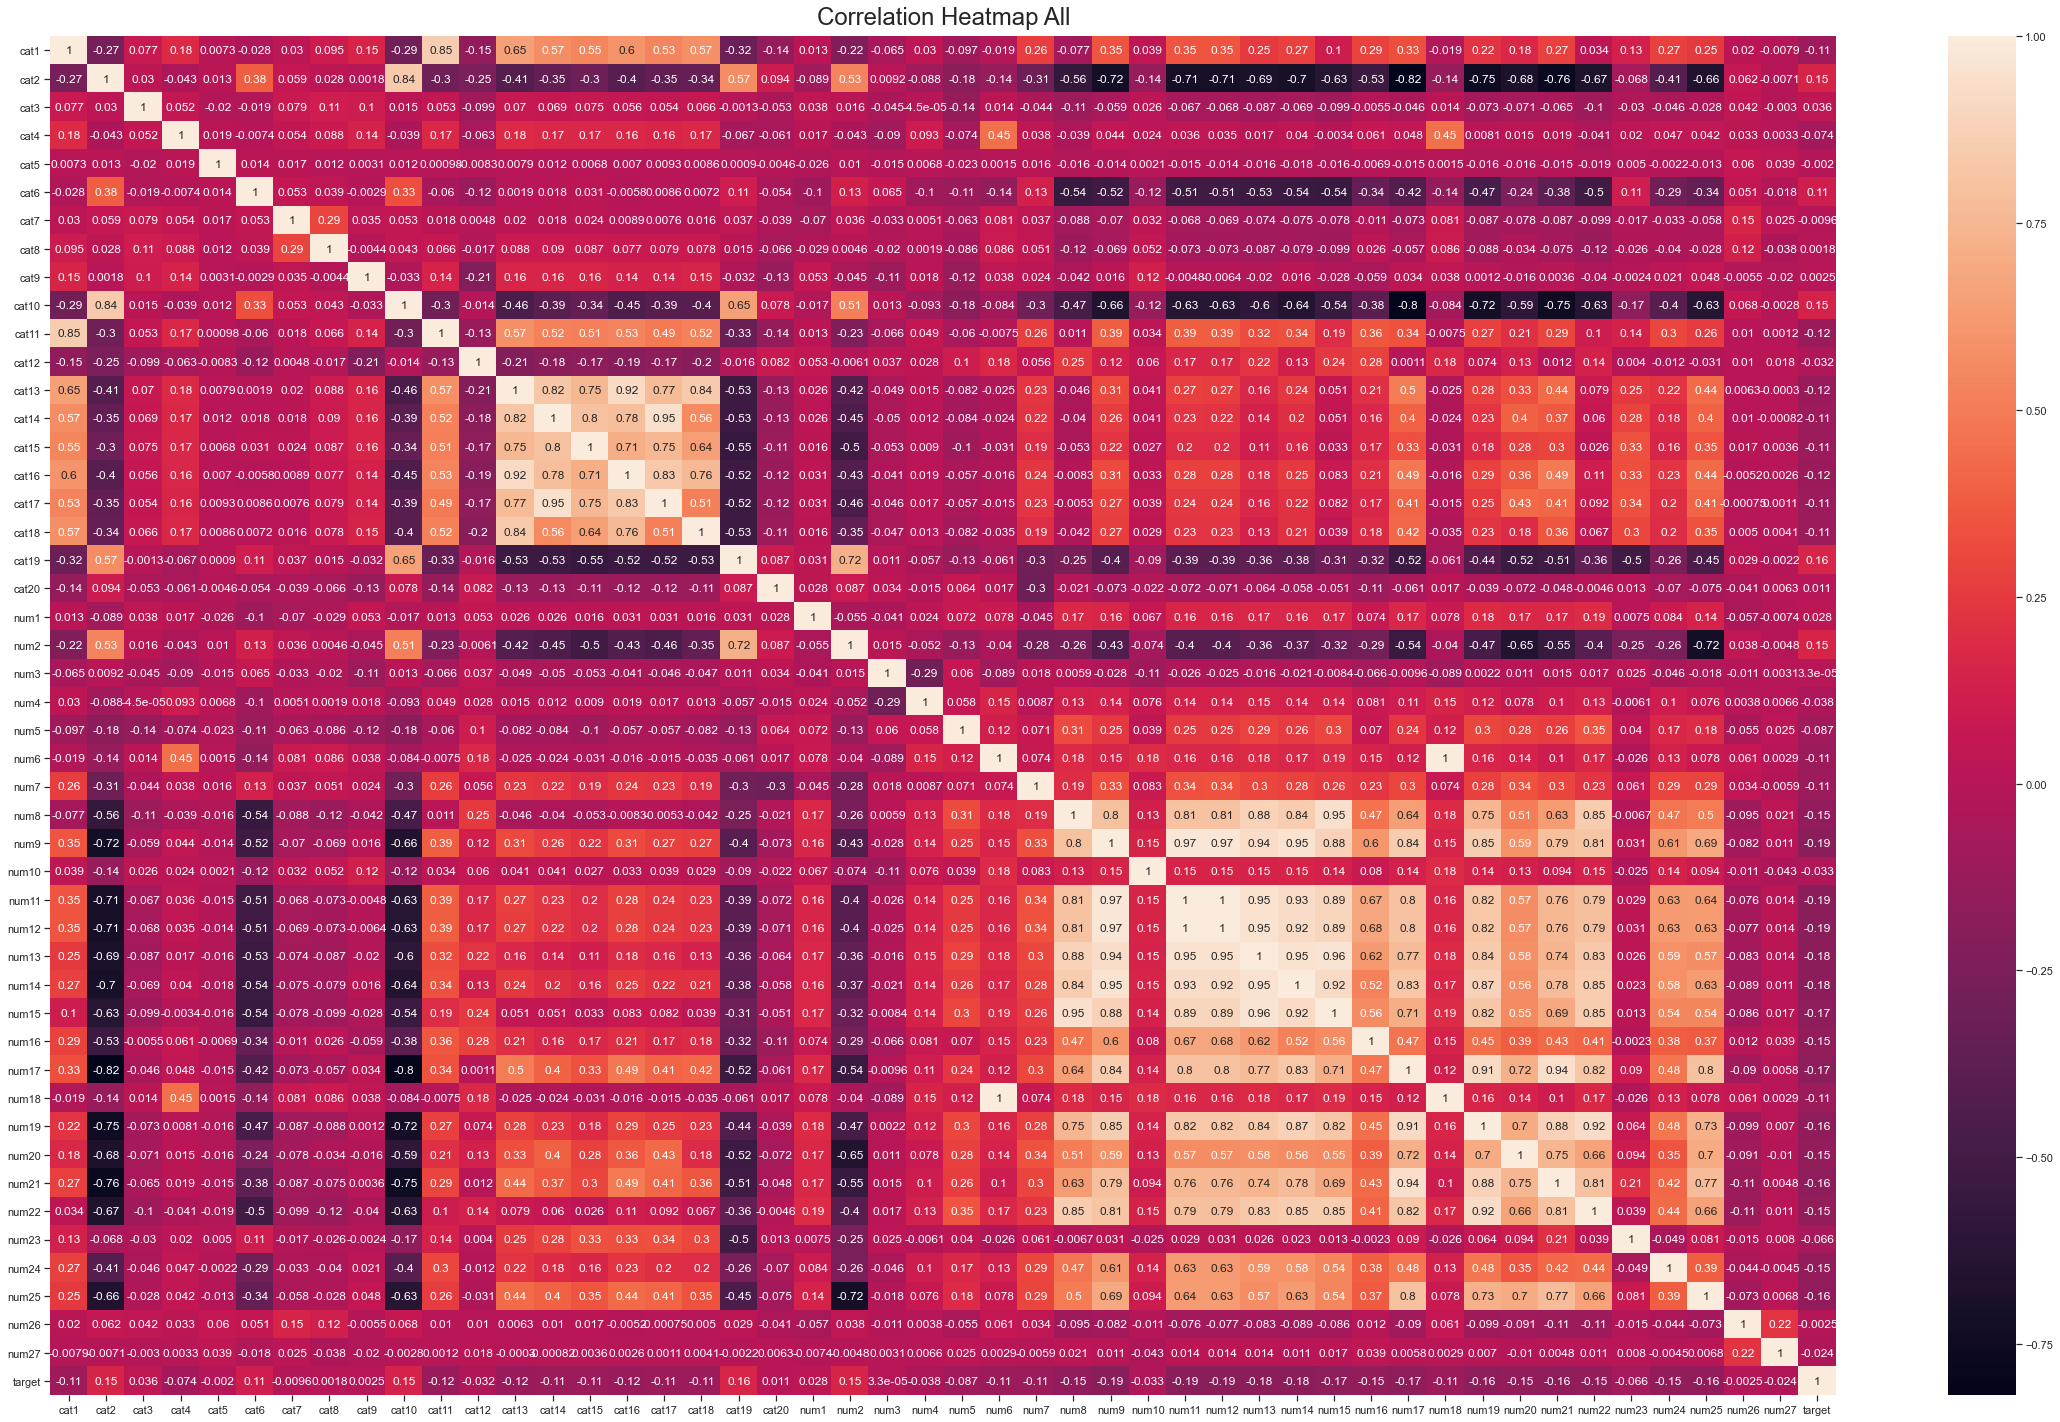

In [37]:
data = df.iloc[:,0:48]
plt.figure(figsize=(40, 25))
heatmap=sns.heatmap(data.corr(method='spearman'), annot=True,yticklabels=data.columns,xticklabels=data.columns)
heatmap.set_title('Correlation Heatmap All', fontdict={'fontsize':24}, pad=12);

In [38]:
#HEAT-MAP
correlation_matrix = df.corr()
df.corr()

,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9,cat10,...,num19,num20,num21,num22,num23,num24,num25,num26,num27,target
cat1,1.000000,-0.359767,0.059102,0.171466,0.005360,-0.049744,0.038100,0.082460,0.134272,-0.328474,...,0.268403,0.242959,0.297513,0.106882,0.107192,0.288349,0.263738,0.011017,-0.003047,-0.126650
cat2,-0.359767,1.000000,0.039606,-0.058287,0.012832,0.334457,0.040286,0.034049,-0.004623,0.805824,...,-0.764348,-0.747277,-0.774914,-0.703718,-0.018568,-0.390512,-0.644711,0.056163,-0.005561,0.176784
cat3,0.059102,0.039606,1.000000,0.050793,-0.027033,-0.017892,0.087566,0.119588,0.088182,0.022643,...,-0.068275,-0.065411,-0.059482,-0.099956,-0.007480,-0.035048,-0.020156,0.034480,0.002340,0.033498
cat4,0.171466,-0.058287,0.050793,1.000000,0.019546,-0.015986,0.055131,0.086802,0.137371,-0.045065,...,0.009659,0.024403,0.015124,-0.032554,0.017092,0.051488,0.039888,0.030695,0.006545,-0.074199
cat5,0.005360,0.012832,-0.027033,0.019546,1.000000,0.010681,0.010697,0.021411,0.003711,0.010881,...,-0.017349,-0.019927,-0.015920,-0.019052,0.009909,-0.002994,-0.014156,0.063170,0.028389,-0.001671
cat6,-0.049744,0.334457,-0.017892,-0.015986,0.010681,1.000000,0.000934,0.018614,0.007592,0.286260,...,-0.443943,-0.216863,-0.366292,-0.448184,0.133541,-0.268253,-0.350248,0.030425,-0.015189,0.120386
cat7,0.038100,0.040286,0.087566,0.055131,0.010697,0.000934,1.000000,0.307651,0.035665,0.029878,...,-0.042200,-0.061273,-0.042589,-0.057314,-0.000783,-0.016289,-0.020278,0.110253,0.030704,-0.008153
cat8,0.082460,0.034049,0.119588,0.086802,0.021411,0.018614,0.307651,1.000000,-0.009573,0.044742,...,-0.094245,-0.037597,-0.084278,-0.118225,-0.023890,-0.027568,-0.039121,0.093921,-0.050861,0.008860
cat9,0.134272,-0.004623,0.088182,0.137371,0.003711,0.007592,0.035665,-0.009573,1.000000,-0.031090,...,-0.012776,-0.018509,-0.003456,-0.059411,0.010337,0.023357,0.045698,-0.002823,-0.007530,0.003037
cat10,-0.328474,0.805824,0.022643,-0.045065,0.010881,0.286260,0.029878,0.044742,-0.031090,1.000000,...,-0.687578,-0.580584,-0.712682,-0.601188,-0.122884,-0.360829,-0.592874,0.059194,0.001414,0.150099


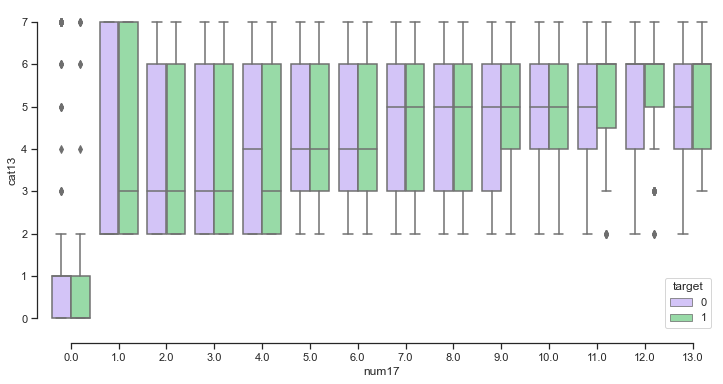

In [39]:
#positively correlated 
#correlation 0.5
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.num17, y=df.cat13,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.rcParams["figure.figsize"] = [0.5, 10]
plt.show()


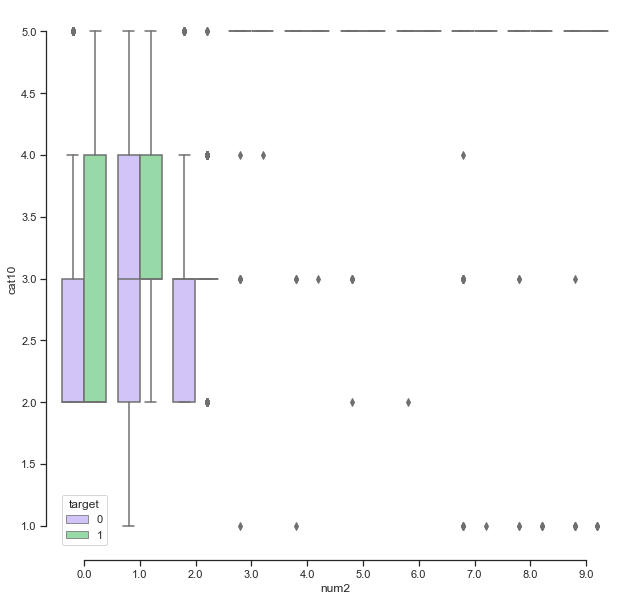

In [43]:
#positively correlated 
#correlation 0.51
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.num2, y=df.cat10,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)

plt.show()

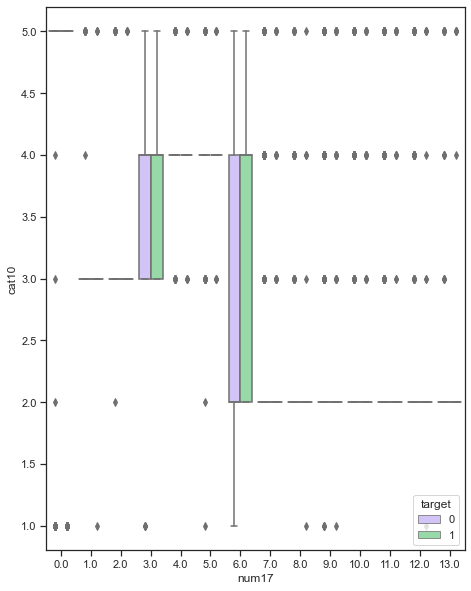

In [62]:
#negatively correlated 
#correlation -0.8
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.num17, y=df.cat10,
            hue=df.target, palette=["m", "g"],
            data=df)

plt.show()

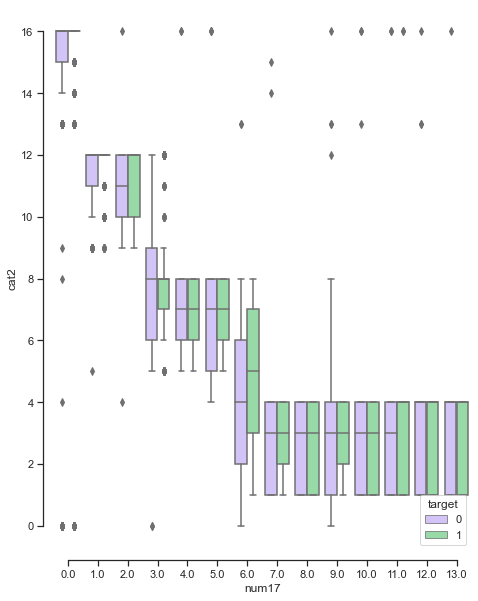

In [63]:
#negatively correlated 
#correlation -0.82
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.num17, y=df.cat2,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.rcParams["figure.figsize"] = [1, 10]
plt.show()

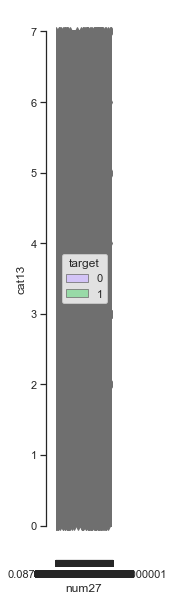

In [64]:
#almost not correlated 
#correlation -0.0003
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.num27, y=df.cat13,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.rcParams["figure.figsize"] = [7.5, 10]
plt.show()

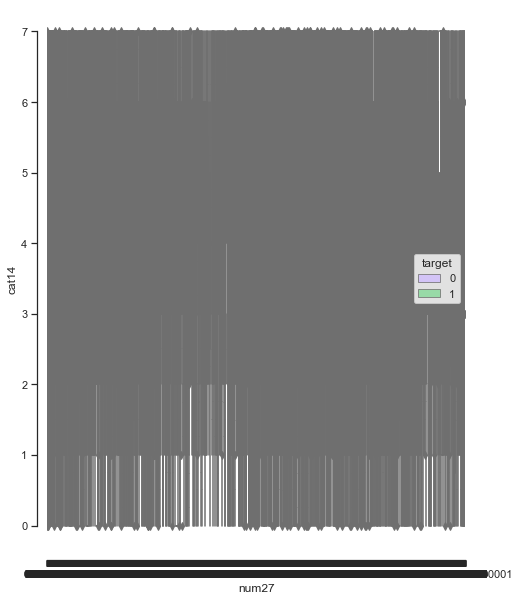

In [65]:
#almost not correlated 
#correlation 0.00082
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.num27, y=df.cat14,
            hue=df.target, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()